# Lesion Segmentation — Mobile-UNet v4 (single consolidated run)

No external backbones, no pretrained weights, no transfer learning. One kernel session,
top to bottom, no restarts.

## Why the previous run (v2) got worse instead of better

Two concrete bugs, not a tuning problem:

1. **Cutout was erasing small lesions.** The cutout patch (8–20% of image side) is the
   same size as a `<1%` lesion's bounding box. It was placed at a random location with no
   awareness of the mask, so it regularly wiped out the only lesion pixels in the image
   while the label still said "lesion present" — label noise concentrated on exactly the
   hardest class.
2. **The lesion crop zoomed to fill the frame; validation never did.** Training showed
   lesions blown up to fill 256×256; validation showed them as tiny specks in a full
   photo. That scale mismatch hurt small lesions most because the scale change was most
   extreme for them.

Both are fixed below (Sections 8–9): cutout is now mask-aware (skips itself rather than
blanking a lesion), and the crop resizes by the same scale a full-frame letterbox would
use, so object size stays identical between training and validation.

## What's different this time, in one run

- **Architecture upgrade**: switched from `mu_b_tuned` (residual + gates + CBAM only) to
  `mu_d_deepsup` — **ASPP** (dilated multi-scale context at the bottleneck) and **deep
  supervision** (auxiliary loss heads at half- and quarter-resolution, not just the final
  output) are both already implemented in this codebase but were never actually turned on
  in any of your training runs. This is the real architecture lever being pulled here,
  not a training-recipe tweak.
- **All four fixed training-recipe changes are enabled together**: scale-consistent crop,
  mask-aware cutout, size-bin oversampling, elastic deformation. Running everything in one
  shot (rather than the arm-by-arm ablation from the last notebook) trades away knowing
  *which one* helped most, in exchange for not needing repeated kernel restarts. Every
  change here is individually fixed and defensible on its own; stacking fixed changes is a
  materially different risk than stacking the buggy ones was.
- **Moderate regularization**: weight decay 3e-5 and dropout 0.12 — between your original
  1e-5 (which showed a 0.12 train/val gap) and the previous overcorrection to 5e-5.
- **SWA** (stochastic weight averaging over the last 6 epochs, with BatchNorm
  recalibration) is on for this run, since it's the only run and there's no reason to save
  it for later.
- Results — overall Dice, the full size-bin breakdown, and which flags were on — are
  appended as one row to `ablation_results.csv` alongside reference rows for your original
  run and the broken v2 run, so this run's outcome is directly comparable to both.

## Kaggle memory/disk notes

- Single run, single architecture, 50 epochs, patience 14 — no self-test loop over all
  four variants (`RUN_VARIANT_SELF_TEST = False`).
- SWA checkpoint pool is capped at 6 epochs and deleted from `/kaggle/working` immediately
  after averaging.
- If you hit `ResourceExhaustedError` (GPU) or a disk-quota error, halve `BATCH_SIZE` in
  Section 2 (ASPP + deep supervision use more memory than `mu_b_tuned` did) — the notebook
  prints the exact fallback steps if that happens.


In [1]:
# ============================================================
# 1. ENVIRONMENT / GPU
# ============================================================
import os
import sys
import json
import time
import math
import random
import warnings
from pathlib import Path
from collections import Counter

os.environ.setdefault("OPENCV_IO_ENABLE_JASPER", "1")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

import tensorflow as tf
from tensorflow.keras import layers, models

warnings.filterwarnings("ignore", category=UserWarning)
try:
    cv2.setLogLevel(0)          # silence "Premature end of JPEG file" (OpenCV 4.x)
except AttributeError:
    try:
        cv2.utils.logging.setLogLevel(cv2.utils.logging.LOG_LEVEL_SILENT)
    except Exception:
        pass

print("Python     :", sys.version.split()[0])
print("TensorFlow :", tf.__version__)
print("Keras      :", tf.keras.__version__)

gpus = tf.config.list_physical_devices("GPU")
print("GPUs found :", len(gpus))

if not gpus:
    raise RuntimeError("STOP: No GPU visible. Do not start the 50-epoch run on CPU.")

try:
    tf.config.set_visible_devices(gpus[0], "GPU")
except Exception as e:
    print("Device-pin note:", e)

for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except Exception as e:
        print("Memory-growth note:", e)

print("Using GPU  :", tf.config.get_visible_devices("GPU"))

from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy("mixed_float16")
print("Mixed precision policy:", mixed_precision.global_policy())

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

print("Environment: OK")


Python     : 3.12.13
TensorFlow : 2.20.0
Keras      : 3.13.2
GPUs found : 2
Using GPU  : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mixed precision policy: <DTypePolicy "mixed_float16">
Environment: OK


In [2]:
# ============================================================
# 2. CONFIGURATION -- single consolidated run, no ablation arms
# ============================================================

VARIANT = "mu_d_deepsup"
# Architecture upgrade: ASPP (dilated multi-scale context at the bottleneck)
# + deep supervision (auxiliary loss heads at half/quarter resolution). Both
# were already implemented in this codebase but never actually trained --
# your best run used mu_b_tuned, which has neither.
VARIANTS = {
    "mu_a_ablation": {
        "base_filters": 16, "depth": 4, "img_size": 256, "batch_size": 16,
        "residual": False, "gates": False, "cbam": True, "aspp": False,
        "deep_sup": False, "activation": "relu",
    },
    "mu_b_tuned": {
        "base_filters": 32, "depth": 4, "img_size": 256, "batch_size": 6,
        "residual": True, "gates": True, "cbam": True, "aspp": False,
        "deep_sup": False, "activation": "swish",
    },
    "mu_c_wide_aspp": {
        "base_filters": 48, "depth": 4, "img_size": 256, "batch_size": 4,
        "residual": True, "gates": True, "cbam": True, "aspp": True,
        "deep_sup": False, "activation": "swish",
    },
    "mu_d_deepsup": {
        "base_filters": 32, "depth": 4, "img_size": 256, "batch_size": 4,
        "residual": True, "gates": True, "cbam": True, "aspp": True,
        "deep_sup": True, "activation": "swish",
    },
}
assert VARIANT in VARIANTS
ARCH = VARIANTS[VARIANT]

RUN_VARIANT_SELF_TEST = False   # single architecture, no need to probe-build all four

# ============================================================
# Every fixed training-recipe change is ON for this single run.
# See the intro markdown for why this differs from arm-by-arm ablation.
# ============================================================
USE_CROP        = True    # scale-consistent windowed crop (Section 8) -- fixed, no zoom
USE_OVERSAMPLE  = True    # size-bin oversampling (Section 8b)
USE_ELASTIC     = True    # elastic deformation (Section 9)
USE_CUTOUT      = True    # mask-aware cutout (Section 9) -- fixed, skips small lesions
USE_SWA         = True    # stochastic weight averaging (Section 19b)

WEIGHT_DECAY    = 3e-5    # between original 1e-5 and the overcorrected 5e-5
DROPOUT         = 0.12
TOTAL_EPOCHS    = 50
EARLY_STOP_PATIENCE = 14

# A label used for filenames and the ablation_results.csv row -- kept as
# "ABLATION_ARM" internally so the rest of the notebook (which logs runs by
# this name) needs no further changes for a single consolidated run.
ABLATION_ARM = "v4_deepsup_all_fixes"

BASE_FILTERS = ARCH["base_filters"]
DEPTH        = ARCH["depth"]
IMG_SIZE     = ARCH["img_size"]
BATCH_SIZE   = ARCH["batch_size"]
GRAD_ACCUM_STEPS = 1
USE_RESIDUAL = ARCH["residual"]
USE_GATES    = ARCH["gates"]
USE_CBAM     = ARCH["cbam"]
USE_ASPP     = ARCH["aspp"]
USE_DEEP_SUP = ARCH["deep_sup"]
ACTIVATION   = ARCH["activation"]
BASE_LR      = 3e-4

EFFECTIVE_BATCH = BATCH_SIZE * GRAD_ACCUM_STEPS

assert IMG_SIZE % (2 ** DEPTH) == 0, f"IMG_SIZE {IMG_SIZE} not divisible by 2**{DEPTH}"

# ---- Paths -------------------------------------------------
DATASET_DIR = Path("/kaggle/input/datasets/annapoornaak/oral-cancer-dataset-mtech-project")
ANNOTATION_FILE = Path("/kaggle/input/datasets/annapoornaak/metadata-zenodo/Annotation.json")
OUTPUT_ROOT = Path("/kaggle/working/Segmentation Output")

RUN_DIR      = OUTPUT_ROOT / f"run_{ABLATION_ARM}"
MASKS_DIR    = OUTPUT_ROOT / "lesion_masks_shared"
ABLATION_CSV = OUTPUT_ROOT / "ablation_results.csv"   # this run appends one row, with reference rows

for d in (OUTPUT_ROOT, RUN_DIR, MASKS_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---- Training ------------------------------------------------
LR_WARMUP_EPOCHS    = 3
GLOBAL_CLIPNORM     = 1.0
CBAM_REDUCTION      = 8
ASPP_MAX_FILTERS    = 192

# ---- SWA -------------------------------------------------------
SWA_LAST_N_EPOCHS  = 6
SWA_BN_RECAL_STEPS = 80

# ---- Loss --------------------------------------------------
TVERSKY_ALPHA  = 0.3
TVERSKY_BETA   = 0.7
TVERSKY_GAMMA  = 0.75
BCE_WEIGHT     = 0.5
TVERSKY_WEIGHT = 0.5
DEEP_SUP_WEIGHTS = {"head_out": 1.0, "aux_out_2": 0.4, "aux_out_4": 0.2}

# ---- Data --------------------------------------------------
INCLUDE_NEGATIVES = False
LETTERBOX_RESIZE  = True
VAL_FRACTION      = 0.20

# ---- Lesion crop (Section 8) -- SCALE-CONSISTENT windowing, not zoom ----
TRAIN_CROP_PROB     = 0.50
CROP_MARGIN_LOW     = 1.30
CROP_MARGIN_HIGH    = 2.30

# ---- Oversampling by lesion-size bin (Section 8b) ----------------
SIZE_BIN_EDGES  = [0.0, 0.01, 0.05, 0.15, 1.0]
SIZE_BIN_LABELS = ["<1%", "1-5%", "5-15%", ">15%"]
SIZE_BIN_TARGET_FREQ = {"<1%": 0.35, "1-5%": 0.30, "5-15%": 0.20, ">15%": 0.15}

# ---- Elastic deform (Section 9) -----------------------------------
ELASTIC_PROB         = 0.30
ELASTIC_ALPHA_RANGE  = (8.0, 20.0)
ELASTIC_SIGMA_RANGE  = (4.0, 7.0)

# ---- Cutout (Section 9) -- MASK-AWARE, fixed version --------------
CUTOUT_PROB          = 0.30
CUTOUT_FRAC_RANGE    = (0.08, 0.20)
CUTOUT_NUM_CANDIDATES = 4
CUTOUT_MAX_LESION_OVERLAP = 0.15

THRESHOLD_GRID = np.round(np.arange(0.10, 0.91, 0.05), 2)
ENSEMBLE_VARIANTS = list(VARIANTS.keys())

print("=" * 70)
print("ARCHITECTURE FAMILY : Mobile-UNet (depthwise separable) ONLY")
print("Pretrained backbone : NONE")
print("=" * 70)
print("Run label         :", ABLATION_ARM)
print("Variant           :", VARIANT, "(base_filters", BASE_FILTERS,
      "| residual", USE_RESIDUAL, "| gates", USE_GATES, "| cbam", USE_CBAM,
      "| aspp", USE_ASPP, "| deep_sup", USE_DEEP_SUP, ")")
print("use_crop          :", USE_CROP, "(scale-consistent, prob", TRAIN_CROP_PROB, ")")
print("use_oversample    :", USE_OVERSAMPLE)
print("use_elastic       :", USE_ELASTIC)
print("use_cutout        :", USE_CUTOUT, "(mask-aware)")
print("use_swa           :", USE_SWA)
print("weight_decay      :", WEIGHT_DECAY, " dropout:", DROPOUT)
print("total_epochs      :", TOTAL_EPOCHS, " patience:", EARLY_STOP_PATIENCE)
print("-" * 70)
print("img_size          :", IMG_SIZE, " batch:", BATCH_SIZE, "x", GRAD_ACCUM_STEPS)
print("Run dir           :", RUN_DIR)
print("Results log       :", ABLATION_CSV)
print("=" * 70)


ARCHITECTURE FAMILY : Mobile-UNet (depthwise separable) ONLY
Pretrained backbone : NONE
Run label         : v4_deepsup_all_fixes
Variant           : mu_d_deepsup (base_filters 32 | residual True | gates True | cbam True | aspp True | deep_sup True )
use_crop          : True (scale-consistent, prob 0.5 )
use_oversample    : True
use_elastic       : True
use_cutout        : True (mask-aware)
use_swa           : True
weight_decay      : 3e-05  dropout: 0.12
total_epochs      : 50  patience: 14
----------------------------------------------------------------------
img_size          : 256  batch: 4 x 1
Run dir           : /kaggle/working/Segmentation Output/run_v4_deepsup_all_fixes
Results log       : /kaggle/working/Segmentation Output/ablation_results.csv


In [3]:
# ============================================================
# 3. LOAD + CHECK COCO JSON
# ============================================================
assert DATASET_DIR.exists(), f"STOP: dataset dir not found: {DATASET_DIR}"
assert ANNOTATION_FILE.exists(), f"STOP: annotation file not found: {ANNOTATION_FILE}"

with open(ANNOTATION_FILE, "r") as f:
    coco = json.load(f)

assert {"images", "annotations", "categories"}.issubset(coco.keys())

name_to_id = {c["name"]: c["id"] for c in coco["categories"]}
assert "Lesion" in name_to_id, f"No 'Lesion' category. Found: {list(name_to_id)}"

CAT_LESION = name_to_id["Lesion"]
CAT_ORAL = name_to_id.get("Oral Cavity")

cat_counts = Counter(a["category_id"] for a in coco["annotations"])

EXPECTED = {"images": 3000, "annotations": 6358, "lesion": 3358, "oral": 3000}
observed = {
    "images": len(coco["images"]),
    "annotations": len(coco["annotations"]),
    "lesion": cat_counts[CAT_LESION],
    "oral": cat_counts.get(CAT_ORAL, 0),
}

print(f"{'key':<14}{'v1 expected':>14}{'observed':>12}{'match':>8}")
for k in EXPECTED:
    print(f"{k:<14}{EXPECTED[k]:>14}{observed[k]:>12}"
          f"{('yes' if EXPECTED[k] == observed[k] else 'NO'):>8}")


key              v1 expected    observed   match
images                  3000        3000     yes
annotations             6358        6358     yes
lesion                  3358        3358     yes
oral                    3000        3000     yes


In [4]:
# ============================================================
# 4. IMAGE ID -> FILE PATH  +  LESION GROUPING
# ============================================================
IMAGE_EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff")

filename_to_path = {}
for p in DATASET_DIR.rglob("*"):
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS:
        filename_to_path.setdefault(p.name, p)

images_info = {img["id"]: img for img in coco["images"]}

image_id_to_path, unmatched = {}, []
for image_id, info in images_info.items():
    fname = Path(info["file_name"]).name
    if fname in filename_to_path:
        image_id_to_path[image_id] = filename_to_path[fname]
    else:
        unmatched.append((image_id, fname))

print("JSON images :", len(images_info))
print("Matched     :", len(image_id_to_path))
print("Unmatched   :", len(unmatched), unmatched[:3])

assert len(image_id_to_path) > 0, "STOP: no images matched."

lesion_by_image = {}
for ann in coco["annotations"]:
    if ann["category_id"] == CAT_LESION:
        lesion_by_image.setdefault(ann["image_id"], []).append(ann)

negative_ids = sorted(set(images_info) - set(lesion_by_image))

print("Images WITH lesion    :", len(lesion_by_image))
print("Images WITHOUT lesion :", len(negative_ids))


JSON images : 3000
Matched     : 3000
Unmatched   : 0 []
Images WITH lesion    : 2271
Images WITHOUT lesion : 729


In [5]:
# ============================================================
# 5. ROBUST IMAGE READER + MASK GENERATION
# ============================================================
def safe_imread(path, flags=cv2.IMREAD_COLOR):
    """Decode an image, tolerating truncated JPEG tails."""
    img = cv2.imread(str(path), flags)
    if img is not None:
        return img
    try:
        buf = np.fromfile(str(path), dtype=np.uint8)
        img = cv2.imdecode(buf, flags)
    except Exception:
        img = None
    return img


def lesion_polygons(image_id):
    """Raw (unclipped) polygon list for an image -- used both for mask
    rendering and for bbox computation in the crop-training pipeline."""
    polys = []
    for ann in lesion_by_image.get(image_id, []):
        seg = ann.get("segmentation", [])
        if not seg:
            continue
        polygons = [seg] if isinstance(seg[0], (int, float)) else seg
        for poly in polygons:
            if len(poly) < 6:
                continue
            polys.append(np.asarray(poly, dtype=np.float32).reshape(-1, 2))
    return polys


def create_lesion_mask(image_id):
    image_path = image_id_to_path.get(image_id)
    if image_path is None:
        return None

    image = safe_imread(image_path, cv2.IMREAD_COLOR)
    if image is None:
        return None

    h, w = image.shape[:2]
    mask = np.zeros((h, w), dtype=np.uint8)

    for pts in lesion_polygons(image_id):
        pts = np.round(pts).astype(np.int32)
        pts[:, 0] = np.clip(pts[:, 0], 0, w - 1)
        pts[:, 1] = np.clip(pts[:, 1], 0, h - 1)
        cv2.fillPoly(mask, [pts], 255)

    return mask


def lesion_bbox_frac(image_id, img_shape=None):
    """Lesion bounding box as (x0,y0,x1,y1) IN FRACTIONS of image width/height.
    Returns None if there is no lesion (crop training then falls back to the
    letterboxed full frame). img_shape lets us avoid re-reading the image
    when the caller already knows h,w."""
    polys = lesion_polygons(image_id)
    if not polys:
        return None
    if img_shape is None:
        image_path = image_id_to_path.get(image_id)
        image = safe_imread(image_path, cv2.IMREAD_COLOR)
        if image is None:
            return None
        h, w = image.shape[:2]
    else:
        h, w = img_shape
    all_pts = np.concatenate(polys, axis=0)
    x0, y0 = all_pts[:, 0].min(), all_pts[:, 1].min()
    x1, y1 = all_pts[:, 0].max(), all_pts[:, 1].max()
    return (float(x0 / w), float(y0 / h), float(x1 / w), float(y1 / h))


_m = create_lesion_mask(next(iter(lesion_by_image)))
assert _m is not None and _m.dtype == np.uint8
assert set(np.unique(_m)).issubset({0, 255}) and np.count_nonzero(_m) > 0
print("Mask unit test: PASS  shape =", _m.shape,
      " positive px =", int(np.count_nonzero(_m)))
del _m


Mask unit test: PASS  shape = (3456, 4608)  positive px = 141110


In [6]:
# ============================================================
# 5b. JPEG INTEGRITY SCAN (NEW)
#     "Premature end of JPEG file" fired on nearly every batch in the
#     previous run. This counts how many files are actually truncated. It
#     does NOT fix corrupted files -- it tells you how big the problem is.
# ============================================================
from PIL import Image as _PILImage

_scan_ids = sorted(image_id_to_path.keys())
_bad_files, _unreadable = [], []

for image_id in tqdm(_scan_ids, desc="JPEG integrity scan"):
    path = image_id_to_path[image_id]
    try:
        with _PILImage.open(path) as im:
            im.verify()          # raises if the file is truncated/corrupt
    except Exception as e:
        _bad_files.append((image_id, path.name, str(e)[:60]))

    img = safe_imread(path, cv2.IMREAD_COLOR)
    if img is None:
        _unreadable.append((image_id, path.name))

print("=" * 60)
print("JPEG INTEGRITY SCAN")
print("=" * 60)
print(f"Files scanned                 : {len(_scan_ids)}")
print(f"Failed PIL.verify() (corrupt) : {len(_bad_files)}  "
      f"({100*len(_bad_files)/max(len(_scan_ids),1):.1f}%)")
print(f"Unreadable even with fallback : {len(_unreadable)}")
if _bad_files:
    print("\\nFirst 10 corrupt files (id, name, error):")
    for row in _bad_files[:10]:
        print(" ", row)
if _unreadable:
    print("\\nUnreadable files (become 'missing_image'/'mask_failed' rows "
          "later and are silently dropped from training):")
    for row in _unreadable[:10]:
        print(" ", row)

_JPEG_SCAN_DF = pd.DataFrame(
    [{"image_id": i, "file": n, "error": e} for i, n, e in _bad_files]
)
_JPEG_SCAN_DF.to_csv(RUN_DIR / "jpeg_integrity_scan.csv", index=False)
print("\\nSaved:", RUN_DIR / "jpeg_integrity_scan.csv")
print("Note: safe_imread() still trains on whatever a truncated file "
      "partially decodes to -- dropping", len(_bad_files),
      "files outright would shrink an already-small dataset further. "
      "If this count is in the hundreds, re-downloading the source "
      "dataset is worth doing before the next full run.")


JPEG integrity scan:   0%|          | 0/3000 [00:00<?, ?it/s]

Premature end of JPEG file


JPEG INTEGRITY SCAN
Files scanned                 : 3000
Failed PIL.verify() (corrupt) : 0  (0.0%)
Unreadable even with fallback : 0
\nSaved: /kaggle/working/Segmentation Output/run_v4_deepsup_all_fixes/jpeg_integrity_scan.csv
Note: safe_imread() still trains on whatever a truncated file partially decodes to -- dropping 0 files outright would shrink an already-small dataset further. If this count is in the hundreds, re-downloading the source dataset is worth doing before the next full run.


In [7]:
# ============================================================
# 6. SEQUENTIAL MASK WRITE + DATASET INDEX (RAM-safe, cached)
# ============================================================
records, failures = [], []

target_ids = sorted(lesion_by_image)
if INCLUDE_NEGATIVES:
    target_ids = sorted(set(target_ids) | set(negative_ids))

for image_id in tqdm(target_ids, desc="Masks"):
    image_path = image_id_to_path.get(image_id)
    if image_path is None:
        failures.append((image_id, "missing_image"))
        continue

    mask_path = MASKS_DIR / f"{image_id}.png"

    if mask_path.exists():
        cached = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        if cached is None:
            mask_path.unlink(missing_ok=True)
            failures.append((image_id, "cache_unreadable"))
            continue
        pos, shape_hw = int(np.count_nonzero(cached)), cached.shape
        del cached
    else:
        mask = create_lesion_mask(image_id)
        if mask is None:
            failures.append((image_id, "mask_failed"))
            continue

        pos, shape_hw = int(np.count_nonzero(mask)), mask.shape
        if pos == 0 and not INCLUDE_NEGATIVES:
            failures.append((image_id, "empty_mask"))
            del mask
            continue

        if not cv2.imwrite(str(mask_path), mask):
            failures.append((image_id, "write_failed"))
            del mask
            continue
        del mask

    bbox = lesion_bbox_frac(image_id, img_shape=shape_hw)

    records.append({
        "image_id": image_id,
        "image_path": str(image_path),
        "mask_path": str(mask_path),
        "lesion_px": pos,
        "lesion_frac": pos / float(shape_hw[0] * shape_hw[1]),
        "bbox_x0": bbox[0] if bbox else np.nan,
        "bbox_y0": bbox[1] if bbox else np.nan,
        "bbox_x1": bbox[2] if bbox else np.nan,
        "bbox_y1": bbox[3] if bbox else np.nan,
    })

dataset_df = pd.DataFrame(records)
assert len(dataset_df) > 0, "STOP: no usable image/mask pairs."
dataset_df.to_csv(RUN_DIR / "lesion_dataset_index.csv", index=False)

print("Usable pairs :", len(dataset_df), " (v1 had 2271)")
print("Failures     :", len(failures), Counter(r for _, r in failures))
print("Images with a usable bbox for crop training:",
      int(dataset_df["bbox_x0"].notna().sum()), "/", len(dataset_df))


Masks:   0%|          | 0/2271 [00:00<?, ?it/s]

Premature end of JPEG file


Usable pairs : 2271  (v1 had 2271)
Failures     : 0 Counter()
Images with a usable bbox for crop training: 2271 / 2271


Mean lesion pixel fraction : 0.1173  (11.73%)
Median                     : 0.0670
Background : foreground    : 7.5 : 1
Images with <1% lesion     : 254
Images with <5% lesion     : 974


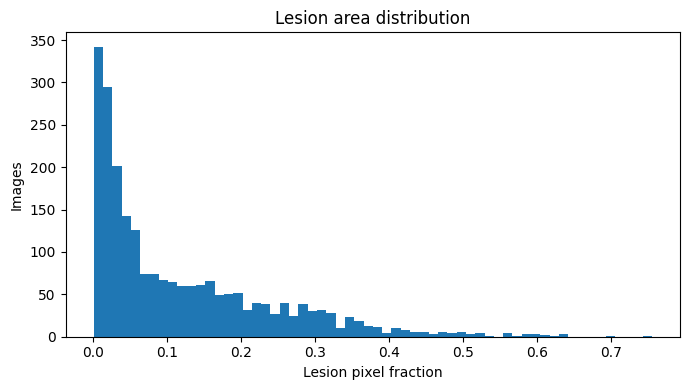

size_bin
<1%      254
1-5%     720
5-15%    587
>15%     710
Name: count, dtype: int64


In [8]:
# ============================================================
# 6a. CLASS-IMBALANCE DIAGNOSTIC
# ============================================================
frac = dataset_df["lesion_frac"].values
pos_rate = float(frac.mean())

print(f"Mean lesion pixel fraction : {pos_rate:.4f}  ({pos_rate*100:.2f}%)")
print(f"Median                     : {np.median(frac):.4f}")
print(f"Background : foreground    : {(1-pos_rate)/max(pos_rate,1e-9):.1f} : 1")
print(f"Images with <1% lesion     : {int((frac < 0.01).sum())}")
print(f"Images with <5% lesion     : {int((frac < 0.05).sum())}")

dataset_df["size_bin"] = pd.cut(dataset_df["lesion_frac"], bins=SIZE_BIN_EDGES,
                                 labels=SIZE_BIN_LABELS)

plt.figure(figsize=(7, 4))
plt.hist(frac, bins=60)
plt.xlabel("Lesion pixel fraction"); plt.ylabel("Images")
plt.title("Lesion area distribution")
plt.tight_layout()
plt.savefig(RUN_DIR / "lesion_area_distribution.png", dpi=140)
plt.show()

print(dataset_df["size_bin"].value_counts().sort_index())


In [9]:
# ============================================================
# 7. STRATIFIED SPLIT
# ============================================================
bins = pd.qcut(dataset_df["lesion_frac"].rank(method="first"),
               q=5, labels=False, duplicates="drop")

train_df, val_df = train_test_split(
    dataset_df, test_size=VAL_FRACTION, random_state=SEED,
    shuffle=True, stratify=bins,
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

assert set(train_df["image_id"]).isdisjoint(set(val_df["image_id"])), "LEAK!"
assert len(train_df) >= BATCH_SIZE, "Train set smaller than one batch."

print("Total :", len(dataset_df), " Train :", len(train_df), " Val :", len(val_df))
print("Mean lesion frac  train:", round(train_df["lesion_frac"].mean(), 4),
      " val:", round(val_df["lesion_frac"].mean(), 4))
print("Split: PASS (stratified, no overlap)")
print()
print("Train size-bin counts:")
print(train_df["size_bin"].value_counts().sort_index())


Total : 2271  Train : 1816  Val : 455
Mean lesion frac  train: 0.1172  val: 0.1177
Split: PASS (stratified, no overlap)

Train size-bin counts:
size_bin
<1%      195
1-5%     584
5-15%    465
>15%     572
Name: count, dtype: int64


In [10]:
# ============================================================
# 8. LOADER + tf.data  (letterbox baseline + SCALE-CONSISTENT lesion window)
#
#    v2 bug being fixed here: the old crop resized the cropped region to FILL
#    IMG_SIZE (a zoom), so lesions looked much bigger in training than in
#    validation's full-frame letterbox. That mismatch is why small lesions
#    collapsed. This version resizes the crop by the SAME scale factor a
#    full-frame letterbox would use, then pastes it into the canvas at its
#    true position -- object pixel size stays identical to validation; only
#    the field of view (how much surrounding context is visible) changes.
# ============================================================
def letterbox(img, size, interp, pad_value=0):
    """Aspect-preserving resize into a size x size canvas."""
    h, w = img.shape[:2]
    scale = size / max(h, w)
    nh, nw = max(1, int(round(h * scale))), max(1, int(round(w * scale)))
    resized = cv2.resize(img, (nw, nh), interpolation=interp)

    top, left = (size - nh) // 2, (size - nw) // 2
    if resized.ndim == 3:
        canvas = np.full((size, size, resized.shape[2]), pad_value, dtype=resized.dtype)
        canvas[top:top + nh, left:left + nw, :] = resized
    else:
        canvas = np.full((size, size), pad_value, dtype=resized.dtype)
        canvas[top:top + nh, left:left + nw] = resized
    return canvas


def _lesion_crop_box(h, w, bx0, by0, bx1, by1, rng):
    """Pick a SQUARE crop box (pixel coords) around a lesion bbox with a
    random margin, clipped to stay inside the image."""
    bw, bh = (bx1 - bx0) * w, (by1 - by0) * h
    cx, cy = (bx0 + bx1) / 2.0 * w, (by0 + by1) / 2.0 * h

    margin = rng.uniform(CROP_MARGIN_LOW, CROP_MARGIN_HIGH)
    side = max(bw, bh) * margin
    side = min(side, min(h, w))   # never larger than the image itself

    jitter = side * 0.10
    cx += rng.uniform(-jitter, jitter)
    cy += rng.uniform(-jitter, jitter)

    x0 = int(round(np.clip(cx - side / 2, 0, w - side)))
    y0 = int(round(np.clip(cy - side / 2, 0, h - side)))
    return x0, y0, int(round(side)), int(round(side))


def _scale_consistent_crop_paste(image, mask, x0, y0, cw, ch, target_size):
    """Crop [y0:y0+ch, x0:x0+cw] out of the FULL-RESOLUTION image/mask, resize
    it by the SAME scale factor a full-frame letterbox of the ORIGINAL image
    would use, and paste it into a target_size x target_size zero canvas at
    the position it would actually occupy in that full letterboxed frame.
    This is the fix for the v2 scale mismatch -- see module docstring above."""
    h, w = image.shape[:2]
    s = target_size / max(h, w)                      # same scale as letterbox()
    full_nh, full_nw = int(round(h * s)), int(round(w * s))
    pad_top, pad_left = (target_size - full_nh) // 2, (target_size - full_nw) // 2

    new_cw, new_ch = max(1, int(round(cw * s))), max(1, int(round(ch * s)))
    crop_img = image[y0:y0 + ch, x0:x0 + cw]
    crop_mask = mask[y0:y0 + ch, x0:x0 + cw]
    resized_img = cv2.resize(crop_img, (new_cw, new_ch), interpolation=cv2.INTER_AREA)
    resized_mask = cv2.resize(crop_mask, (new_cw, new_ch), interpolation=cv2.INTER_NEAREST)

    place_x = int(round(pad_left + x0 * s))
    place_y = int(round(pad_top + y0 * s))

    canvas_img = np.zeros((target_size, target_size, 3), dtype=image.dtype)
    canvas_mask = np.zeros((target_size, target_size), dtype=mask.dtype)

    px0, py0 = max(0, place_x), max(0, place_y)
    ex, ey = min(target_size, place_x + new_cw), min(target_size, place_y + new_ch)
    sx0, sy0 = px0 - place_x, py0 - place_y

    if ex > px0 and ey > py0:
        canvas_img[py0:ey, px0:ex] = resized_img[sy0:sy0 + (ey - py0), sx0:sx0 + (ex - px0)]
        canvas_mask[py0:ey, px0:ex] = resized_mask[sy0:sy0 + (ey - py0), sx0:sx0 + (ex - px0)]

    return canvas_img, canvas_mask


def _load_np(image_path, mask_path, bbox, do_crop_flag):
    image_path = image_path.numpy().decode("utf-8")
    mask_path = mask_path.numpy().decode("utf-8")
    bbox = bbox.numpy()
    do_crop = bool(do_crop_flag.numpy())

    image = safe_imread(image_path, cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Unreadable image: {image_path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f"Unreadable mask: {mask_path}")

    h, w = image.shape[:2]
    has_bbox = bool(np.all(np.isfinite(bbox)))

    if do_crop and has_bbox:
        rng = np.random.default_rng()
        x0, y0, cw, ch = _lesion_crop_box(h, w, *bbox.tolist(), rng)
        image, mask = _scale_consistent_crop_paste(image, mask, x0, y0, cw, ch, IMG_SIZE)
    elif LETTERBOX_RESIZE:
        image = letterbox(image, IMG_SIZE, cv2.INTER_AREA, 0)
        mask = letterbox(mask, IMG_SIZE, cv2.INTER_NEAREST, 0)
    else:
        image = cv2.resize(image, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
        mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)

    return (np.ascontiguousarray(image, dtype=np.float32),
            np.ascontiguousarray((mask > 127).astype(np.float32)[..., None]))


def tf_load(image_path, mask_path, bbox, training):
    do_crop = training and USE_CROP and (tf.random.uniform([]) < TRAIN_CROP_PROB)
    image, mask = tf.py_function(
        _load_np, [image_path, mask_path, bbox, do_crop],
        [tf.float32, tf.float32])
    image.set_shape([IMG_SIZE, IMG_SIZE, 3])
    mask.set_shape([IMG_SIZE, IMG_SIZE, 1])
    return image, mask


In [11]:
# ============================================================
# 8b. OVERSAMPLING BY LESION-SIZE BIN (NEW)
#     Small-lesion images are a minority of the training set (see the
#     bin counts printed in Section 7). Rather than let the natural
#     frequency decide how often the model sees them, each size bin
#     becomes its own tf.data.Dataset (looping, shuffled) and
#     sample_from_datasets mixes them at fixed target weights every
#     epoch -- so <1% and 1-5% lesions show up far more often than
#     their raw count would produce.
# ============================================================
def _bin_dataset(df_bin, training):
    paths = df_bin["image_path"].values
    masks = df_bin["mask_path"].values
    bbox = df_bin[["bbox_x0", "bbox_y0", "bbox_x1", "bbox_y1"]].values.astype(np.float32)
    ds = tf.data.Dataset.from_tensor_slices((paths, masks, bbox))
    if training:
        ds = ds.shuffle(max(len(df_bin), 1), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.repeat()
    ds = ds.map(lambda p, m, b: tf_load(p, m, b, training),
                num_parallel_calls=tf.data.AUTOTUNE, deterministic=not training)
    return ds


def make_train_dataset_oversampled(df):
    present_bins = [b for b in SIZE_BIN_LABELS if (df["size_bin"] == b).sum() > 0]
    weights = np.array([SIZE_BIN_TARGET_FREQ[b] for b in present_bins], dtype=np.float64)
    weights = weights / weights.sum()

    bin_datasets = [_bin_dataset(df[df["size_bin"] == b].reset_index(drop=True), training=True)
                    for b in present_bins]

    print("Oversampling weights (renormalized over present bins):")
    for b, wgt in zip(present_bins, weights):
        n = int((df["size_bin"] == b).sum())
        print(f"  {b:<8} n={n:<5} natural_freq={n/len(df):.3f}  target_freq={wgt:.3f}")

    ds = tf.data.Dataset.sample_from_datasets(bin_datasets, weights=weights.tolist(), seed=SEED)
    return ds


def make_dataset(df, training):
    if training and USE_OVERSAMPLE:
        ds = make_train_dataset_oversampled(df)
    else:
        paths = df["image_path"].values
        masks = df["mask_path"].values
        bbox = df[["bbox_x0", "bbox_y0", "bbox_x1", "bbox_y1"]].values.astype(np.float32)
        ds = tf.data.Dataset.from_tensor_slices((paths, masks, bbox))
        if training:
            ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.map(lambda p, m, b: tf_load(p, m, b, training),
                    num_parallel_calls=tf.data.AUTOTUNE, deterministic=not training)

    if training:
        ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE, deterministic=False)

    if USE_DEEP_SUP:
        ds = ds.map(add_deep_sup_targets, num_parallel_calls=tf.data.AUTOTUNE)

    ds = ds.batch(BATCH_SIZE, drop_remainder=training)
    return ds.prefetch(tf.data.AUTOTUNE)


def main_target(y):
    """Extract the full-resolution mask regardless of deep-supervision mode."""
    return y["head_out"] if isinstance(y, dict) else y


In [12]:
# ============================================================
# 9. AUGMENTATION (orientation-safe, geometry-consistent)
#    flip + affine + color jitter: unchanged from the original notebook,
#    always on, not implicated in the v2 regression.
#    elastic deform / cutout: gated by USE_ELASTIC / USE_CUTOUT (Section 2).
#
#    v2 bug being fixed here: cutout picked a random location with NO
#    awareness of the mask. For a <1% lesion, the cutout patch (8-20% of
#    image side) is the same size as the lesion's bounding box, so it
#    regularly erased the only lesion pixels in the image while the label
#    still said "lesion present" -- label noise concentrated on the hardest
#    class. Fixed version below samples a few candidate placements and
#    either uses the one that overlaps the lesion least, or skips cutout
#    for that sample entirely if even the best candidate overlaps too much.
# ============================================================
def _rand_affine(image, mask):
    """Rotation +/-15 deg, shift +/-8%, zoom 0.9-1.1 -- identical for both."""
    angle = tf.random.uniform([], -15.0, 15.0) * math.pi / 180.0
    zoom = tf.random.uniform([], 0.90, 1.10)
    dx = tf.random.uniform([], -0.08, 0.08) * IMG_SIZE
    dy = tf.random.uniform([], -0.08, 0.08) * IMG_SIZE

    cos_a, sin_a = tf.cos(angle) / zoom, tf.sin(angle) / zoom
    cx = cy = IMG_SIZE / 2.0

    a2 = cx - cx * cos_a + cy * sin_a + dx
    b2 = cy - cx * sin_a - cy * cos_a + dy
    transform = tf.stack([cos_a, -sin_a, a2, sin_a, cos_a, b2, 0.0, 0.0])[None, :]

    stacked = tf.concat([image, mask], axis=-1)[None, ...]
    warped = tf.raw_ops.ImageProjectiveTransformV3(
        images=stacked, transforms=transform,
        output_shape=tf.constant([IMG_SIZE, IMG_SIZE], tf.int32),
        interpolation="BILINEAR", fill_mode="CONSTANT", fill_value=0.0,
    )[0]

    return warped[..., :3], tf.cast(warped[..., 3:] > 0.5, tf.float32)


def _elastic_deform_np(image, mask, alpha, sigma):
    """Classic Simard-style elastic deformation via a smoothed random
    displacement field, applied identically to image and mask. Mask is
    squeezed to 2D before cv2.remap (cv2 is picky about a trailing size-1
    channel axis) and re-expanded after -- this was unhandled in v2."""
    shape = image.shape[:2]
    dx = cv2.GaussianBlur((np.random.rand(*shape).astype(np.float32) * 2 - 1),
                          (0, 0), sigma) * alpha
    dy = cv2.GaussianBlur((np.random.rand(*shape).astype(np.float32) * 2 - 1),
                          (0, 0), sigma) * alpha

    xs, ys = np.meshgrid(np.arange(shape[1]), np.arange(shape[0]))
    map_x = (xs + dx).astype(np.float32)
    map_y = (ys + dy).astype(np.float32)

    warped_img = cv2.remap(image, map_x, map_y, interpolation=cv2.INTER_LINEAR,
                           borderMode=cv2.BORDER_CONSTANT, borderValue=0)

    mask2d = mask[..., 0] if mask.ndim == 3 else mask
    warped_mask2d = cv2.remap(mask2d, map_x, map_y, interpolation=cv2.INTER_NEAREST,
                              borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    return warped_img.astype(np.float32), warped_mask2d[..., None].astype(np.float32)


def _elastic_deform_tf(image, mask):
    alpha = tf.random.uniform([], *ELASTIC_ALPHA_RANGE)
    sigma = tf.random.uniform([], *ELASTIC_SIGMA_RANGE)
    img_out, mask_out = tf.numpy_function(
        _elastic_deform_np, [image, mask, alpha, sigma], [tf.float32, tf.float32])
    img_out.set_shape([IMG_SIZE, IMG_SIZE, 3])
    mask_out.set_shape([IMG_SIZE, IMG_SIZE, 1])
    return img_out, tf.cast(mask_out > 0.5, tf.float32)


def _cutout(image, mask):
    """Mask-aware cutout (fixed). Tries CUTOUT_NUM_CANDIDATES random square
    patches on the IMAGE only, measures each one's pixel overlap with the
    lesion mask, and applies whichever candidate overlaps least -- but only
    if that best candidate still stays under CUTOUT_MAX_LESION_OVERLAP.
    Otherwise this is a no-op for this sample: better to skip an augmentation
    than to silently erase the only positive label in a small-lesion image."""
    lesion_total = tf.reduce_sum(mask) + 1e-6

    holes, overlaps = [], []
    for _ in range(CUTOUT_NUM_CANDIDATES):
        frac = tf.random.uniform([], *CUTOUT_FRAC_RANGE)
        side = tf.cast(frac * IMG_SIZE, tf.int32)
        cy = tf.random.uniform([], 0, IMG_SIZE, dtype=tf.int32)
        cx = tf.random.uniform([], 0, IMG_SIZE, dtype=tf.int32)

        y0 = tf.clip_by_value(cy - side // 2, 0, IMG_SIZE)
        x0 = tf.clip_by_value(cx - side // 2, 0, IMG_SIZE)
        y1 = tf.clip_by_value(y0 + side, 0, IMG_SIZE)
        x1 = tf.clip_by_value(x0 + side, 0, IMG_SIZE)

        yy = tf.range(IMG_SIZE)[:, None]
        xx = tf.range(IMG_SIZE)[None, :]
        hole = tf.cast((yy >= y0) & (yy < y1) & (xx >= x0) & (xx < x1), tf.float32)[..., None]

        overlap = tf.reduce_sum(mask * hole) / lesion_total
        holes.append(hole)
        overlaps.append(overlap)

    overlaps_t = tf.stack(overlaps)
    holes_t = tf.stack(holes, axis=0)
    best_idx = tf.argmin(overlaps_t)
    best_hole = tf.gather(holes_t, best_idx)
    best_overlap = tf.gather(overlaps_t, best_idx)

    return tf.cond(best_overlap <= CUTOUT_MAX_LESION_OVERLAP,
                   lambda: image * (1.0 - best_hole),
                   lambda: image)


def augment(image, mask):
    if tf.random.uniform([]) > 0.5:                 # horizontal flip only
        image = tf.image.flip_left_right(image)
        mask = tf.image.flip_left_right(mask)

    if tf.random.uniform([]) > 0.3:
        image, mask = _rand_affine(image, mask)

    if USE_ELASTIC and tf.random.uniform([]) < ELASTIC_PROB:
        image, mask = _elastic_deform_tf(image, mask)

    image = tf.image.random_brightness(image, 20.0)          # on [0,255]
    image = tf.image.random_contrast(image, 0.85, 1.15)
    image = tf.image.random_saturation(image, 0.85, 1.15)
    image = tf.image.random_hue(image, 0.02)
    image = tf.clip_by_value(image, 0.0, 255.0)

    if USE_CUTOUT and tf.random.uniform([]) < CUTOUT_PROB:
        image = _cutout(image, mask)

    image.set_shape([IMG_SIZE, IMG_SIZE, 3])
    mask.set_shape([IMG_SIZE, IMG_SIZE, 1])
    return image, mask


def add_deep_sup_targets(image, mask):
    """Targets keyed by output name so Keras matches them unambiguously."""
    m2 = tf.image.resize(mask, [IMG_SIZE // 2, IMG_SIZE // 2], method="nearest")
    m4 = tf.image.resize(mask, [IMG_SIZE // 4, IMG_SIZE // 4], method="nearest")
    return image, {"head_out": mask, "aux_out_2": m2, "aux_out_4": m4}


In [13]:
# ============================================================
# 9b. BUILD train_ds / val_ds
# ============================================================
train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)

_xb, _yb = next(iter(train_ds))
_main = main_target(_yb)

print("Image batch:", _xb.shape, "range",
      float(tf.reduce_min(_xb)), "-", float(tf.reduce_max(_xb)))
print("Mask batch :", _main.shape, "unique", np.unique(_main.numpy()))
assert np.all(np.isfinite(_xb.numpy()))
assert set(np.unique(_main.numpy())).issubset({0.0, 1.0})
print("Pipeline: PASS")


I0000 00:00:1790101212.181947      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5


Oversampling weights (renormalized over present bins):
  <1%      n=195   natural_freq=0.107  target_freq=0.350
  1-5%     n=584   natural_freq=0.322  target_freq=0.300
  5-15%    n=465   natural_freq=0.256  target_freq=0.200
  >15%     n=572   natural_freq=0.315  target_freq=0.150
Image batch: (4, 256, 256, 3) range 0.0 - 255.0
Mask batch : (4, 256, 256, 1) unique [0. 1.]
Pipeline: PASS


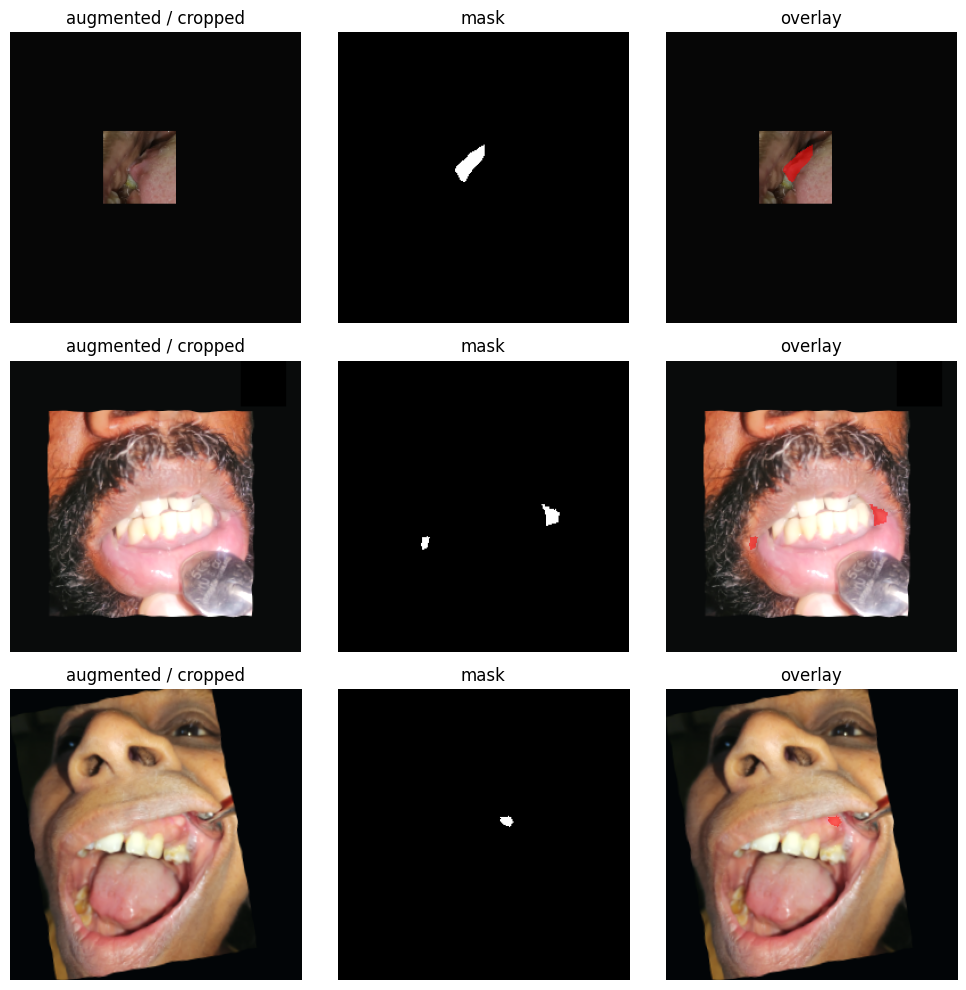

Lesion-fraction of these 3 mask crops: [0.0058, 0.0035, 0.0011] -- should generally read higher than the raw lesion_frac column
since TRAIN_CROP_PROB = 0.5 of batches are lesion-centered crops.


In [14]:
# ============================================================
# 9c. VISUAL CHECK OF AUGMENTED / CROPPED BATCH
# ============================================================
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for i in range(3):
    img = _xb[i].numpy().astype(np.uint8)
    msk = _main[i].numpy()[..., 0]
    ov = img.copy()
    sel = msk > 0.5
    ov[sel] = (0.45 * ov[sel] + 0.55 * np.array([255, 0, 0])).astype(np.uint8)

    axes[i, 0].imshow(img);              axes[i, 0].set_title("augmented / cropped")
    axes[i, 1].imshow(msk, cmap="gray"); axes[i, 1].set_title("mask")
    axes[i, 2].imshow(ov);               axes[i, 2].set_title("overlay")
    for c in range(3):
        axes[i, c].axis("off")

plt.tight_layout()
plt.savefig(RUN_DIR / "augmentation_check.png", dpi=140)
plt.show()
print("Lesion-fraction of these 3 mask crops:",
      [round(float((_main[i].numpy() > 0.5).mean()), 4) for i in range(3)],
      "-- should generally read higher than the raw lesion_frac column")
print("since TRAIN_CROP_PROB =", TRAIN_CROP_PROB, "of batches are lesion-centered crops.")


In [15]:
# ============================================================
# 10. LOSSES + METRICS (registered so model.save() works)
# ============================================================
SMOOTH = 1e-6


def _flat(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    n = tf.shape(y_true)[0]
    return tf.reshape(y_true, [n, -1]), tf.reshape(y_pred, [n, -1])


@tf.keras.utils.register_keras_serializable(package="MobileUNetLesion")
def dice_coef(y_true, y_pred):
    yt, yp = _flat(y_true, y_pred)
    inter = tf.reduce_sum(yt * yp, axis=1)
    denom = tf.reduce_sum(yt, axis=1) + tf.reduce_sum(yp, axis=1)
    return tf.reduce_mean((2.0 * inter + SMOOTH) / (denom + SMOOTH))


@tf.keras.utils.register_keras_serializable(package="MobileUNetLesion")
def iou_coef(y_true, y_pred):
    yt, yp = _flat(y_true, y_pred)
    inter = tf.reduce_sum(yt * yp, axis=1)
    union = tf.reduce_sum(yt, axis=1) + tf.reduce_sum(yp, axis=1) - inter
    return tf.reduce_mean((inter + SMOOTH) / (union + SMOOTH))


@tf.keras.utils.register_keras_serializable(package="MobileUNetLesion")
def bin_dice(y_true, y_pred):
    """Hard Dice at 0.5 -- the reported number."""
    yt, yp = _flat(y_true, tf.cast(y_pred > 0.5, tf.float32))
    inter = tf.reduce_sum(yt * yp, axis=1)
    denom = tf.reduce_sum(yt, axis=1) + tf.reduce_sum(yp, axis=1)
    return tf.reduce_mean((2.0 * inter + SMOOTH) / (denom + SMOOTH))


@tf.keras.utils.register_keras_serializable(package="MobileUNetLesion")
def bin_iou(y_true, y_pred):
    yt, yp = _flat(y_true, tf.cast(y_pred > 0.5, tf.float32))
    inter = tf.reduce_sum(yt * yp, axis=1)
    union = tf.reduce_sum(yt, axis=1) + tf.reduce_sum(yp, axis=1) - inter
    return tf.reduce_mean((inter + SMOOTH) / (union + SMOOTH))


def tversky_index(y_true, y_pred, alpha=TVERSKY_ALPHA, beta=TVERSKY_BETA):
    yt, yp = _flat(y_true, y_pred)
    tp = tf.reduce_sum(yt * yp, axis=1)
    fp = tf.reduce_sum((1.0 - yt) * yp, axis=1)
    fn = tf.reduce_sum(yt * (1.0 - yp), axis=1)
    return tf.reduce_mean((tp + SMOOTH) / (tp + alpha * fp + beta * fn + SMOOTH))


def focal_tversky_loss(y_true, y_pred, gamma=TVERSKY_GAMMA):
    return tf.pow(1.0 - tversky_index(y_true, y_pred), gamma)


@tf.keras.utils.register_keras_serializable(package="MobileUNetLesion")
def combined_loss(y_true, y_pred):
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred))
    return BCE_WEIGHT * bce + TVERSKY_WEIGHT * focal_tversky_loss(y_true, y_pred)


METRICS = [dice_coef, iou_coef, bin_dice, bin_iou]

# quick numerical sanity check
_t = tf.constant(np.random.randint(0, 2, (2, 8, 8, 1)).astype(np.float32))
_p = tf.constant(np.random.rand(2, 8, 8, 1).astype(np.float32))
for fn in (dice_coef, iou_coef, bin_dice, bin_iou, combined_loss):
    v = float(fn(_t, _p))
    assert np.isfinite(v), f"{fn.__name__} not finite"
assert abs(float(dice_coef(_t, _t)) - 1.0) < 1e-4, "dice_coef(y,y) != 1"
assert float(combined_loss(_t, _t)) < 0.05, "loss on perfect prediction too high"
del _t, _p

print("Losses and metrics defined and sanity-checked.")
print("Loss = 0.5*BCE + 0.5*FocalTversky(alpha=0.3, beta=0.7, gamma=0.75)")


Losses and metrics defined and sanity-checked.
Loss = 0.5*BCE + 0.5*FocalTversky(alpha=0.3, beta=0.7, gamma=0.75)


In [16]:
# ============================================================
# 11. LAYER-NAME REGISTRY
#    Guarantees the duplicate-name crash can never happen again.
# ============================================================
class NameRegistry:
    """Hands out guaranteed-unique layer names and records every one."""

    def __init__(self):
        self.used = set()

    def reset(self):
        self.used = set()

    def __call__(self, name):
        if name in self.used:
            raise ValueError(
                f"Duplicate layer name generated: '{name}'. "
                "This is a builder bug -- fix the name prefix."
            )
        self.used.add(name)
        return name


NAMES = NameRegistry()
print("Name registry ready. Every layer name is asserted unique at build time.")


Name registry ready. Every layer name is asserted unique at build time.


In [17]:
# ============================================================
# 12. MOBILE-UNET BLOCKS (100% depthwise separable)
# ============================================================
@tf.keras.utils.register_keras_serializable(package="MobileUNetLesion")
class CBAM(layers.Layer):
    """Channel + spatial attention. No Lambda -> clean .keras serialization."""

    def __init__(self, reduction_ratio=8, spatial_kernel=7, **kwargs):
        super().__init__(**kwargs)
        self.reduction_ratio = int(reduction_ratio)
        self.spatial_kernel = int(spatial_kernel)

    def build(self, input_shape):
        c = int(input_shape[-1])
        r = max(c // self.reduction_ratio, 4)
        self.mlp1 = layers.Dense(r, activation="relu", name="ch_reduce")
        self.mlp2 = layers.Dense(c, activation=None, name="ch_expand")
        self.sp_conv = layers.Conv2D(1, self.spatial_kernel, padding="same",
                                     activation="sigmoid", name="sp_conv")
        super().build(input_shape)

    def call(self, x):
        avg = tf.reduce_mean(x, axis=[1, 2])
        mx = tf.reduce_max(x, axis=[1, 2])
        att = tf.nn.sigmoid(self.mlp2(self.mlp1(avg)) + self.mlp2(self.mlp1(mx)))
        x = x * att[:, None, None, :]

        sp = tf.concat([tf.reduce_mean(x, -1, keepdims=True),
                        tf.reduce_max(x, -1, keepdims=True)], axis=-1)
        return x * self.sp_conv(sp)

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"reduction_ratio": self.reduction_ratio,
                    "spatial_kernel": self.spatial_kernel})
        return cfg


def sep_block(x, filters, prefix, act, dilation=1):
    """Separable conv -> BN -> activation."""
    x = layers.SeparableConv2D(
        filters, 3, padding="same", use_bias=False, dilation_rate=dilation,
        name=NAMES(f"{prefix}_sep"))(x)
    x = layers.BatchNormalization(name=NAMES(f"{prefix}_bn"))(x)
    return layers.Activation(act, name=NAMES(f"{prefix}_act"))(x)


def residual_sep_block(x, filters, prefix, act, dropout=0.0):
    """Two separable convs + 1x1 projection shortcut."""
    shortcut = layers.Conv2D(filters, 1, padding="same", use_bias=False,
                             name=NAMES(f"{prefix}_sc"))(x)
    shortcut = layers.BatchNormalization(name=NAMES(f"{prefix}_sc_bn"))(shortcut)

    y = sep_block(x, filters, f"{prefix}_a", act)
    if dropout > 0:
        y = layers.SpatialDropout2D(dropout, name=NAMES(f"{prefix}_inner_drop"))(y)
    y = layers.SeparableConv2D(filters, 3, padding="same", use_bias=False,
                               name=NAMES(f"{prefix}_b_sep"))(y)
    y = layers.BatchNormalization(name=NAMES(f"{prefix}_b_bn"))(y)

    out = layers.Add(name=NAMES(f"{prefix}_add"))([shortcut, y])
    return layers.Activation(act, name=NAMES(f"{prefix}_out"))(out)


def double_block(x, filters, prefix, residual, act, dropout):
    """Either two plain separable convs (v1 style) or one residual block."""
    if residual:
        return residual_sep_block(x, filters, prefix, act, dropout)
    x = sep_block(x, filters, f"{prefix}_a", act)
    x = sep_block(x, filters, f"{prefix}_b", act)
    if dropout > 0:
        x = layers.SpatialDropout2D(dropout, name=NAMES(f"{prefix}_inner_drop"))(x)
    return x


def attention_gate(skip, gating, filters, prefix):
    """Additive attention gate applied to a skip connection."""
    g = layers.Conv2D(filters, 1, padding="same", name=NAMES(f"{prefix}_g"))(gating)
    s = layers.Conv2D(filters, 1, padding="same", name=NAMES(f"{prefix}_x"))(skip)
    a = layers.Add(name=NAMES(f"{prefix}_add"))([g, s])
    a = layers.Activation("relu", name=NAMES(f"{prefix}_relu"))(a)
    psi = layers.Conv2D(1, 1, padding="same", activation="sigmoid",
                        name=NAMES(f"{prefix}_psi"))(a)
    return layers.Multiply(name=NAMES(f"{prefix}_mul"))([skip, psi])


def sep_aspp(x, filters, prefix, act, rates=(1, 2, 4, 8)):
    """Separable atrous spatial pyramid. Branch width is capped so the
    48-filter variant does not explode to millions of parameters."""
    branch_f = int(min(filters, ASPP_MAX_FILTERS))

    branches = [layers.Conv2D(branch_f, 1, padding="same", use_bias=False,
                              name=NAMES(f"{prefix}_b0_conv"))(x)]
    for i, r in enumerate(rates[1:], start=1):
        branches.append(sep_block(x, branch_f, f"{prefix}_b{i}", act, dilation=r))

    pooled = layers.GlobalAveragePooling2D(
        keepdims=True, name=NAMES(f"{prefix}_gap"))(x)
    pooled = layers.Conv2D(branch_f, 1, padding="same", use_bias=False,
                           name=NAMES(f"{prefix}_gap_conv"))(pooled)
    pooled = layers.UpSampling2D(size=(int(x.shape[1]), int(x.shape[2])),
                                 interpolation="bilinear",
                                 name=NAMES(f"{prefix}_gap_up"))(pooled)
    branches.append(pooled)

    merged = layers.Concatenate(name=NAMES(f"{prefix}_cat"))(branches)
    merged = layers.Conv2D(branch_f, 1, padding="same", use_bias=False,
                           name=NAMES(f"{prefix}_proj"))(merged)
    merged = layers.BatchNormalization(name=NAMES(f"{prefix}_proj_bn"))(merged)
    return layers.Activation(act, name=NAMES(f"{prefix}_proj_act"))(merged)


print("Mobile-UNet blocks defined (no external backbone, no pretrained weights).")


Mobile-UNet blocks defined (no external backbone, no pretrained weights).


In [18]:
# ============================================================
# 13. MOBILE-UNET BUILDER
# ============================================================
def build_mobile_unet(img_size, base_filters, depth,
                      residual, gates, cbam, aspp, deep_sup,
                      dropout, act, name="mobile_unet"):
    NAMES.reset()

    inputs = layers.Input(shape=(img_size, img_size, 3), name=NAMES("input_image"))
    x = layers.Rescaling(1.0 / 255.0, name=NAMES("rescale"))(inputs)

    # ---------------- Encoder ----------------
    skips, filters = [], base_filters
    for i in range(depth):
        enc_drop = dropout * 0.5 if i >= depth - 2 else 0.0
        x = double_block(x, filters, f"enc{i}", residual, act, enc_drop)
        skips.append(x)
        x = layers.MaxPooling2D(2, name=NAMES(f"enc{i}_pool"))(x)
        filters *= 2

    # ---------------- Bottleneck ----------------
    if aspp:
        x = sep_aspp(x, filters, "bneck_aspp", act)
        filters = int(x.shape[-1])
    else:
        x = double_block(x, filters, "bneck", residual, act, 0.0)

    if cbam:
        x = CBAM(CBAM_REDUCTION, name=NAMES("bottleneck_cbam"))(x)

    if dropout > 0:
        x = layers.SpatialDropout2D(dropout, name=NAMES("bottleneck_drop"))(x)

    # ---------------- Decoder ----------------
    aux_outputs = {}
    dec_filters = base_filters * (2 ** (depth - 1))

    for i in reversed(range(depth)):
        x = layers.UpSampling2D(2, interpolation="bilinear",
                                name=NAMES(f"dec{i}_up"))(x)

        skip = skips[i]
        if gates:
            skip = attention_gate(skip, x, max(dec_filters // 2, 8), f"dec{i}_gate")

        x = layers.Concatenate(name=NAMES(f"dec{i}_cat"))([x, skip])
        x = double_block(x, dec_filters, f"dec{i}", residual, act,
                         dropout if i >= 2 else 0.0)

        if deep_sup and i in (1, 2):
            head_name = f"aux_out_{2 ** i}"
            aux_outputs[head_name] = layers.Conv2D(
                1, 1, activation="sigmoid", dtype="float32",
                name=NAMES(head_name))(x)

        dec_filters = max(dec_filters // 2, base_filters)

    main_out = layers.Conv2D(1, 1, activation="sigmoid", dtype="float32",
                             name=NAMES("head_out"))(x)

    if deep_sup:
        outputs = [main_out, aux_outputs["aux_out_2"], aux_outputs["aux_out_4"]]
        model = models.Model(inputs, outputs, name=name)
    else:
        model = models.Model(inputs, main_out, name=name)

    all_names = [l.name for l in model.layers]
    dupes = [n for n, c in Counter(all_names).items() if c > 1]
    assert not dupes, f"Duplicate layer names survived the registry: {dupes}"

    return model


print("Builder defined.")


Builder defined.


### Build-time self-test

All four variants are constructed and immediately discarded. If any variant would
raise a duplicate-name error, it surfaces here — before any training time is spent.


In [19]:
# ============================================================
# 14b. SELF-TEST -- BUILD EVERY VARIANT (optional, see Section 2)
# ============================================================
if not RUN_VARIANT_SELF_TEST:
    print("Skipped (RUN_VARIANT_SELF_TEST = False in Section 2).")
    print("The selected variant is still verified by the hard preflight below.")
else:
    print(f"{'variant':<18}{'params':>12}{'FP32 MB':>10}{'outputs':>10}  status")
    print("-" * 64)

    _size_table = {}

    for _name, _cfg in VARIANTS.items():
        tf.keras.backend.clear_session()
        try:
            _m = build_mobile_unet(
                img_size=_cfg["img_size"], base_filters=_cfg["base_filters"],
                depth=_cfg["depth"], residual=_cfg["residual"], gates=_cfg["gates"],
                cbam=_cfg["cbam"], aspp=_cfg["aspp"], deep_sup=_cfg["deep_sup"],
                dropout=_cfg.get("dropout", DROPOUT), act=_cfg["activation"], name=f"probe_{_name}",
            )
            _p = int(_m.count_params())
            _mb = _p * 4 / (1024 ** 2)
            _n_out = len(_m.outputs)
            _size_table[_name] = {"params": _p, "fp32_mb": round(_mb, 2)}
            print(f"{_name:<18}{_p:>12,}{_mb:>10.2f}{_n_out:>10}  OK")
            del _m
        except Exception as e:
            print(f"{_name:<18}{'-':>12}{'-':>10}{'-':>10}  FAIL: {e}")
            raise

    print("-" * 64)
    print(f"{'v1_original':<18}{311319:>12,}{311319 * 4 / 1024 ** 2:>10.2f}{1:>10}  reference")
    print()
    print("All variants build cleanly. No duplicate layer names.")

    tf.keras.backend.clear_session()


Skipped (RUN_VARIANT_SELF_TEST = False in Section 2).
The selected variant is still verified by the hard preflight below.


In [20]:
# ============================================================
# 15. BUILD THE SELECTED MODEL
# ============================================================
tf.keras.backend.clear_session()
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

model = build_mobile_unet(
    img_size=IMG_SIZE,
    base_filters=BASE_FILTERS,
    depth=DEPTH,
    residual=USE_RESIDUAL,
    gates=USE_GATES,
    cbam=USE_CBAM,
    aspp=USE_ASPP,
    deep_sup=USE_DEEP_SUP,
    dropout=DROPOUT,
    act=ACTIVATION,
    name=f"lesion_{VARIANT}",
)

total_params = int(model.count_params())
trainable_params = int(sum(np.prod(v.shape) for v in model.trainable_weights))
non_trainable_params = total_params - trainable_params
fp32_mb = total_params * 4 / (1024 ** 2)

V1_PARAMS, V1_DICE, V1_IOU = 311319, 0.30052751, 0.19818199

print("=" * 66)
print("MODEL SIZE")
print("=" * 66)
print(f"{'Model':<24}{model.name}")
print(f"{'Total params':<24}{total_params:>14,}")
print(f"{'Trainable params':<24}{trainable_params:>14,}")
print(f"{'Non-trainable (BN)':<24}{non_trainable_params:>14,}")
print(f"{'FP32 weights (MB)':<24}{fp32_mb:>14.2f}")
print(f"{'FP16 activations (~)':<24}{'mixed_float16 active -- ~2x less activation RAM':>14}")
print(f"{'INT8 estimate (MB)':<24}{total_params / (1024 ** 2):>14.2f}")
print("-" * 66)
print(f"{'v1 total params':<24}{V1_PARAMS:>14,}")
print(f"{'v1 FP32 (MB)':<24}{V1_PARAMS * 4 / 1024 ** 2:>14.2f}")
print(f"{'Capacity vs v1':<24}{total_params / V1_PARAMS:>13.2f}x")
print("=" * 66)
print("Separable conv layers :",
      sum(1 for l in model.layers if isinstance(l, layers.SeparableConv2D)))
print("Total layers          :", len(model.layers))
print("Output(s)             :", model.output_shape)
print("Architecture family   : Mobile-UNet only (no external backbone)")


MODEL SIZE
Model                   lesion_mu_d_deepsup
Total params                 1,191,117
Trainable params             1,183,821
Non-trainable (BN)               7,296
FP32 weights (MB)                 4.54
FP16 activations (~)    mixed_float16 active -- ~2x less activation RAM
INT8 estimate (MB)                1.14
------------------------------------------------------------------
v1 total params                311,319
v1 FP32 (MB)                      1.19
Capacity vs v1                   3.83x
Separable conv layers : 19
Total layers          : 136
Output(s)             : [(None, 256, 256, 1), (None, 128, 128, 1), (None, 64, 64, 1)]
Architecture family   : Mobile-UNet only (no external backbone)


In [21]:
# ============================================================
# 16. HARD PREFLIGHT -- NOTHING TRAINS BEFORE THIS PASSES
# ============================================================
checks = []

vx, vy = next(iter(val_ds))
vy_main = main_target(vy)

out = model(vx, training=False)
pred = out[0] if isinstance(out, (list, tuple)) else out

checks.append(("output shape matches target", tuple(pred.shape) == tuple(vy_main.shape)))
checks.append(("prediction finite", bool(np.all(np.isfinite(pred.numpy())))))
checks.append(("prediction in [0,1]",
               float(pred.numpy().min()) >= 0.0 and float(pred.numpy().max()) <= 1.0))
checks.append(("masks binary", set(np.unique(vy_main.numpy())).issubset({0.0, 1.0})))
checks.append(("images in [0,255]",
               float(vx.numpy().min()) >= 0.0 and float(vx.numpy().max()) <= 255.0))

loss_val = float(combined_loss(vy_main, pred))
checks.append(("loss finite", bool(np.isfinite(loss_val))))
checks.append(("train batches > 0", len(train_df) // BATCH_SIZE > 0))
checks.append(("no train/val leak",
               set(train_df["image_id"]).isdisjoint(set(val_df["image_id"]))))
checks.append(("unique layer names",
               len({l.name for l in model.layers}) == len(model.layers)))

if USE_DEEP_SUP:
    checks.append(("3 outputs for deep supervision", len(model.outputs) == 3))
    checks.append(("aux target keys match outputs",
                   set(vy.keys()) == {"head_out", "aux_out_2", "aux_out_4"}))

with tf.GradientTape() as tape:
    o = model(vx, training=True)
    p = o[0] if isinstance(o, (list, tuple)) else o
    l = combined_loss(vy_main, p)
grads = tape.gradient(l, model.trainable_weights)
nonzero = sum(1 for g in grads if g is not None and float(tf.reduce_max(tf.abs(g))) > 0)
checks.append((f"gradients flow ({nonzero}/{len(grads)})", nonzero > 0.8 * len(grads)))

print(f"{'check':<44}{'result':>8}")
print("-" * 52)
for label, ok in checks:
    print(f"{label:<44}{'PASS' if ok else 'FAIL':>8}")
print("-" * 52)
assert all(ok for _, ok in checks), "STOP: preflight failed -- fix before training."
print("Preflight: ALL PASS")


check                                         result
----------------------------------------------------
output shape matches target                     PASS
prediction finite                               PASS
prediction in [0,1]                             PASS
masks binary                                    PASS
images in [0,255]                               PASS
loss finite                                     PASS
train batches > 0                               PASS
no train/val leak                               PASS
unique layer names                              PASS
3 outputs for deep supervision                  PASS
aux target keys match outputs                   PASS
gradients flow (137/141)                        PASS
----------------------------------------------------
Preflight: ALL PASS


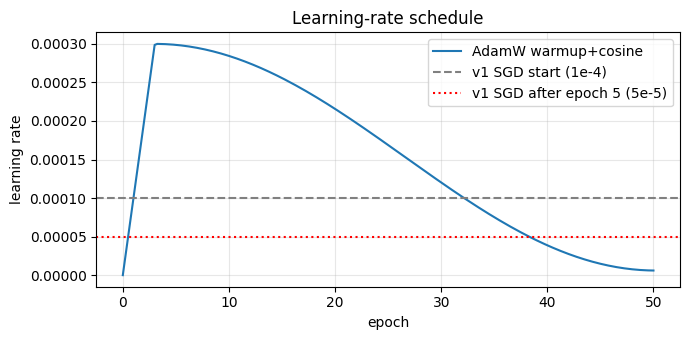

Steps/epoch (weight updates): 454
Physical batch  : 4  Grad accum steps: 1  Effective batch: 4
Monitor     : val_head_out_bin_dice
Compile: PASS


In [22]:
# ============================================================
# 17. LR SCHEDULE + COMPILE  (with gradient accumulation)
# ============================================================
steps_per_epoch = max(1, len(train_df) // BATCH_SIZE // GRAD_ACCUM_STEPS)


@tf.keras.utils.register_keras_serializable(package="MobileUNetLesion")
class WarmupCosine(tf.keras.optimizers.schedules.LearningRateSchedule):
    """Linear warmup then cosine decay. Registered so model.save() works."""

    def __init__(self, base_lr, total_steps, warmup_steps, min_lr_ratio=0.02):
        super().__init__()
        self.base_lr = float(base_lr)
        self.total_steps = int(total_steps)
        self.warmup_steps = int(warmup_steps)
        self.min_lr_ratio = float(min_lr_ratio)

    def __call__(self, step):
        step = tf.cast(step, tf.float32)
        warm = tf.cast(tf.maximum(self.warmup_steps, 1), tf.float32)
        total = tf.cast(tf.maximum(self.total_steps, 1), tf.float32)

        warm_lr = self.base_lr * (step / warm)
        prog = tf.clip_by_value((step - warm) / tf.maximum(total - warm, 1.0), 0.0, 1.0)
        cos_lr = self.base_lr * (
            self.min_lr_ratio
            + (1.0 - self.min_lr_ratio) * 0.5 * (1.0 + tf.cos(math.pi * prog))
        )
        return tf.where(step < warm, warm_lr, cos_lr)

    def get_config(self):
        return {"base_lr": self.base_lr, "total_steps": self.total_steps,
                "warmup_steps": self.warmup_steps, "min_lr_ratio": self.min_lr_ratio}


schedule = WarmupCosine(
    BASE_LR,
    total_steps=TOTAL_EPOCHS * steps_per_epoch,
    warmup_steps=LR_WARMUP_EPOCHS * steps_per_epoch,
)

optimizer = tf.keras.optimizers.AdamW(
    learning_rate=schedule,
    weight_decay=WEIGHT_DECAY,
    global_clipnorm=GLOBAL_CLIPNORM,
    # gradient_accumulation_steps: accumulates GRAD_ACCUM_STEPS physical
    # batches before each weight update, so EFFECTIVE_BATCH (Section 2)
    # is what the optimizer actually "sees" per step even though only
    # BATCH_SIZE fits in GPU memory at once. Supported natively by
    # tf.keras.optimizers.AdamW (Keras 3 / TF >= 2.16); if your TF build
    # is older this argument is silently ignored -- check the printed
    # optimizer config below and upgrade TF if grad accumulation matters.
    gradient_accumulation_steps=GRAD_ACCUM_STEPS if GRAD_ACCUM_STEPS > 1 else None,
)

if mixed_precision.global_policy().name == "mixed_float16":
    optimizer = mixed_precision.LossScaleOptimizer(optimizer)
    print("LossScaleOptimizer enabled (mixed_float16 training).")

if USE_DEEP_SUP:
    model.compile(
        optimizer=optimizer,
        loss={k: combined_loss for k in DEEP_SUP_WEIGHTS},
        loss_weights=dict(DEEP_SUP_WEIGHTS),
        metrics={"head_out": METRICS},
        steps_per_execution=1,
    )
    MONITOR = "val_head_out_bin_dice"
    DICE_COL, IOU_COL = "head_out_bin_dice", "head_out_bin_iou"
else:
    model.compile(optimizer=optimizer, loss=combined_loss, metrics=METRICS,
                  steps_per_execution=1)
    MONITOR = "val_bin_dice"
    DICE_COL, IOU_COL = "bin_dice", "bin_iou"

lrs = [float(schedule(s)) for s in range(0, TOTAL_EPOCHS * steps_per_epoch,
                                         max(1, steps_per_epoch // 4))]
plt.figure(figsize=(7, 3.5))
plt.plot(np.linspace(0, TOTAL_EPOCHS, len(lrs)), lrs, label="AdamW warmup+cosine")
plt.axhline(1e-4, ls="--", c="gray", label="v1 SGD start (1e-4)")
plt.axhline(5e-5, ls=":", c="r", label="v1 SGD after epoch 5 (5e-5)")
plt.xlabel("epoch"); plt.ylabel("learning rate"); plt.legend(); plt.grid(alpha=.3)
plt.title("Learning-rate schedule")
plt.tight_layout()
plt.savefig(RUN_DIR / "lr_schedule.png", dpi=140)
plt.show()

print("Steps/epoch (weight updates):", steps_per_epoch)
print("Physical batch  :", BATCH_SIZE, " Grad accum steps:", GRAD_ACCUM_STEPS,
      " Effective batch:", EFFECTIVE_BATCH)
print("Monitor     :", MONITOR)
print("Compile: PASS")


In [23]:
# ============================================================
# 18. TRAIN
#     Ablation arms train for TOTAL_EPOCHS (25, patience 8) and skip the SWA
#     checkpoint pool entirely (USE_SWA=False) to save Kaggle disk/GPU-hours.
#     Only combined_winners (TOTAL_EPOCHS=50, USE_SWA=True) keeps checkpoints.
# ============================================================
BEST_WEIGHTS  = RUN_DIR / f"{ABLATION_ARM}_best.weights.h5"
FINAL_MODEL   = RUN_DIR / f"{ABLATION_ARM}_final.keras"
FINAL_WEIGHTS = RUN_DIR / f"{ABLATION_ARM}_final.weights.h5"
HISTORY_CSV   = RUN_DIR / f"{ABLATION_ARM}_history.csv"
SWA_POOL_DIR  = RUN_DIR / f"{ABLATION_ARM}_swa_pool"
if USE_SWA:
    SWA_POOL_DIR.mkdir(parents=True, exist_ok=True)


class EpochTimer(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.times = []

    def on_epoch_begin(self, epoch, logs=None):
        self._t0 = time.time()

    def on_epoch_end(self, epoch, logs=None):
        self.times.append(time.time() - self._t0)


class SwaCheckpointPool(tf.keras.callbacks.Callback):
    """Keeps weight snapshots for the most recent SWA_LAST_N_EPOCHS epochs
    on disk (rolling window -- oldest is deleted as new ones arrive)."""

    def __init__(self, pool_dir, keep_last_n):
        super().__init__()
        self.pool_dir = Path(pool_dir)
        self.keep_last_n = keep_last_n
        self.saved = []

    def on_epoch_end(self, epoch, logs=None):
        path = self.pool_dir / f"epoch_{epoch:03d}.weights.h5"
        self.model.save_weights(str(path))
        self.saved.append(path)
        while len(self.saved) > self.keep_last_n:
            old = self.saved.pop(0)
            old.unlink(missing_ok=True)


timer = EpochTimer()
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        str(BEST_WEIGHTS), monitor=MONITOR, mode="max",
        save_best_only=True, save_weights_only=True, verbose=1),
    tf.keras.callbacks.EarlyStopping(
        monitor=MONITOR, mode="max", patience=EARLY_STOP_PATIENCE,
        restore_best_weights=True, verbose=1),
    tf.keras.callbacks.CSVLogger(str(HISTORY_CSV), append=False),
    tf.keras.callbacks.TerminateOnNaN(),
    timer,
]

swa_pool = None
if USE_SWA:
    swa_pool = SwaCheckpointPool(SWA_POOL_DIR, SWA_LAST_N_EPOCHS)
    callbacks.append(swa_pool)

print("=" * 70)
print("TRAINING MOBILE-UNET -- arm:", ABLATION_ARM)
print("=" * 70)
print("Base filters :", BASE_FILTERS, "| depth:", DEPTH, "| size:", IMG_SIZE)
print("Params       :", f"{total_params:,}", f"({fp32_mb:.2f} MB FP32)")
print("Optimizer    : AdamW warmup+cosine, base LR", BASE_LR,
      "| grad accum", GRAD_ACCUM_STEPS, "| weight decay", WEIGHT_DECAY,
      "| dropout", DROPOUT)
print("Loss         : 0.5*BCE + 0.5*FocalTversky(0.3, 0.7)")
print("Epochs       :", TOTAL_EPOCHS, "| early stop patience:", EARLY_STOP_PATIENCE)
print("crop / oversample / elastic / cutout :",
      USE_CROP, "/", USE_OVERSAMPLE, "/", USE_ELASTIC, "/", USE_CUTOUT)
print("SWA          :", USE_SWA)
print("=" * 70)

t_start = time.time()

try:
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=TOTAL_EPOCHS,
        steps_per_epoch=steps_per_epoch,
        callbacks=callbacks,
        verbose=1,
    )
except tf.errors.ResourceExhaustedError as e:
    print()
    print("=" * 70)
    print("OUT OF GPU MEMORY")
    print("=" * 70)
    print(f"Current config: img_size={IMG_SIZE}, batch_size={BATCH_SIZE}, "
          f"base_filters={BASE_FILTERS}, mixed_precision=True")
    print()
    print("Fix, in order of preference (edit Section 2, restart kernel, rerun):")
    print(f"  1. Halve batch_size, set grad_accum_steps=2 to hold effective batch: "
          f"{BATCH_SIZE} -> {max(1, BATCH_SIZE // 2)}")
    print(f"  2. Drop base_filters: {BASE_FILTERS} -> {max(16, BASE_FILTERS // 2)}")
    print("  3. Confirm mixed precision is active (printed at the top of Section 1)")
    print("  4. If Kaggle shows 2 GPUs, confirm no other notebook session holds one")
    print("=" * 70)
    raise
training_seconds = time.time() - t_start

print()
print("=" * 70)
print("TRAINING COMPLETE")
print("=" * 70)
print("Epochs run    :", len(history.history["loss"]))
print("Total minutes :", round(training_seconds / 60.0, 2), " (v1: 236.43)")
print("Mean epoch (s):", round(float(np.mean(timer.times)), 1))
if USE_SWA and swa_pool is not None:
    print("SWA pool has  :", len(swa_pool.saved), "checkpoint(s) on disk:",
          [p.name for p in swa_pool.saved])
else:
    print("SWA pool      : skipped for this arm (USE_SWA=False)")


TRAINING MOBILE-UNET -- arm: v4_deepsup_all_fixes
Base filters : 32 | depth: 4 | size: 256
Params       : 1,191,117 (4.54 MB FP32)
Optimizer    : AdamW warmup+cosine, base LR 0.0003 | grad accum 1 | weight decay 3e-05 | dropout 0.12
Loss         : 0.5*BCE + 0.5*FocalTversky(0.3, 0.7)
Epochs       : 50 | early stop patience: 14
crop / oversample / elastic / cutout : True / True / True / True
SWA          : True
Epoch 1/50


2026-09-22 18:21:14.096552: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-22 18:21:14.236624: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-22 18:21:15.120786: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-22 18:21:15.287225: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-22 18:21:22.482917: E external/local_xla/xla/stream_

454/454 ━━━━━━━━━━━━━━━━━━━━ 0s 272ms/step - aux_out_2_loss: 0.7056 - aux_out_4_loss: 0.7606 - head_out_bin_dice: 0.1772 - head_out_bin_iou: 0.1124 - head_out_dice_coef: 0.1125 - head_out_iou_coef: 0.0651 - head_out_loss: 0.6978 - loss: 1.1322

2026-09-22 18:24:46.766387: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-22 18:24:46.905760: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-22 18:24:47.740731: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-22 18:24:47.903182: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Epoch 1: val_head_out_bin_dice improved from None to 0.00026, saving model to /kaggle/working/Segmentation Output/run_v4_deepsup_all_fixes/v4_deepsup_all_fixes_best.weights.h5

Epoch 1: finished saving model to /kaggle/working/Segmentation Output/run_v4_deepsup_all_fixes/v4_deepsup_all_fixes_best.weights.h5
454/454 ━━━━━━━━━━━━━━━━━━━━ 271s 409ms/step - aux_out_2_loss: 0.6165 - aux_out_4_loss: 0.6429 - head_out_bin_dice: 0.2571 - head_out_bin_iou: 0.1715 - head_out_dice_coef: 0.1571 - head_out_iou_coef: 0.0946 - head_out_loss: 0.5979 - loss: 0.9731 - val_aux_out_2_loss: 0.6004 - val_aux_out_4_loss: 0.5856 - val_head_out_bin_dice: 2.5680e-04 - val_head_out_bin_iou: 1.3603e-04 - val_head_out_dice_coef: 0.1248 - val_head_out_iou_coef: 0.0692 - val_head_out_loss: 0.5896 - val_loss: 0.9469
Epoch 2/50
 14/454 ━━━━━━━━━━━━━━━━━━━━ 1:26 198ms/step - aux_out_2_loss: 0.5040 - aux_out_4_loss: 0.4998 - head_out_bin_dice: 0.3350 - head_out_bin_iou: 0.2414 - head_out_dice_coef: 0.2441 - head_out_io

Premature end of JPEG file


... (37 outputs left out)

Premature end of JPEG file



Epoch 40: val_head_out_bin_dice did not improve from 0.55157
454/454 ━━━━━━━━━━━━━━━━━━━━ 190s 419ms/step - aux_out_2_loss: 0.2830 - aux_out_4_loss: 0.2869 - head_out_bin_dice: 0.6184 - head_out_bin_iou: 0.4869 - head_out_dice_coef: 0.5974 - head_out_iou_coef: 0.4619 - head_out_loss: 0.2825 - loss: 0.4530 - val_aux_out_2_loss: 0.3877 - val_aux_out_4_loss: 0.3896 - val_head_out_bin_dice: 0.5392 - val_head_out_bin_iou: 0.4235 - val_head_out_dice_coef: 0.5223 - val_head_out_iou_coef: 0.4009 - val_head_out_loss: 0.3871 - val_loss: 0.6203
Epoch 41/50
454/454 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step - aux_out_2_loss: 0.2862 - aux_out_4_loss: 0.2908 - head_out_bin_dice: 0.6193 - head_out_bin_iou: 0.4894 - head_out_dice_coef: 0.5979 - head_out_iou_coef: 0.4641 - head_out_loss: 0.2854 - loss: 0.4581
Epoch 41: val_head_out_bin_dice did not improve from 0.55157
454/454 ━━━━━━━━━━━━━━━━━━━━ 144s 318ms/step - aux_out_2_loss: 0.2812 - aux_out_4_loss: 0.2857 - head_out_bin_dice: 0.6237 - head_out_bin_iou:

Premature end of JPEG file


454/454 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - aux_out_2_loss: 0.2750 - aux_out_4_loss: 0.2802 - head_out_bin_dice: 0.6332 - head_out_bin_iou: 0.5036 - head_out_dice_coef: 0.6136 - head_out_iou_coef: 0.4793 - head_out_loss: 0.2740 - loss: 0.4400
Epoch 43: val_head_out_bin_dice did not improve from 0.55157
454/454 ━━━━━━━━━━━━━━━━━━━━ 166s 366ms/step - aux_out_2_loss: 0.2727 - aux_out_4_loss: 0.2778 - head_out_bin_dice: 0.6391 - head_out_bin_iou: 0.5090 - head_out_dice_coef: 0.6187 - head_out_iou_coef: 0.4841 - head_out_loss: 0.2719 - loss: 0.4365 - val_aux_out_2_loss: 0.4046 - val_aux_out_4_loss: 0.4068 - val_head_out_bin_dice: 0.5260 - val_head_out_bin_iou: 0.4076 - val_head_out_dice_coef: 0.5107 - val_head_out_iou_coef: 0.3876 - val_head_out_loss: 0.4042 - val_loss: 0.6475
Epoch 44/50
454/454 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - aux_out_2_loss: 0.2823 - aux_out_4_loss: 0.2868 - head_out_bin_dice: 0.6159 - head_out_bin_iou: 0.4843 - head_out_dice_coef: 0.5965 - head_out_iou_coef: 0.4609

In [24]:
# ============================================================
# 19b. SWA -- STOCHASTIC WEIGHT AVERAGING
#      Only runs when USE_SWA=True (combined_winners arm). Ablation arms skip
#      this entirely to save Kaggle GPU-hours and disk. After averaging, the
#      checkpoint pool files are deleted from /kaggle/working -- leaving them
#      around across a sweep of ablation runs is the fastest way to blow the
#      20GB working-directory quota.
# ============================================================
swa_model = None
swa_dice = None
best_dice_single = None

if not USE_SWA:
    print("USE_SWA=False for this arm -- skipping SWA, best-epoch weights stand as-is.")
else:
    swa_ckpts = sorted(SWA_POOL_DIR.glob("epoch_*.weights.h5"))
    print("Averaging", len(swa_ckpts), "checkpoint(s):", [p.name for p in swa_ckpts])

    if len(swa_ckpts) < 2:
        print("Fewer than 2 checkpoints in the pool (short run or early stop before "
              "the pool filled) -- skipping SWA, best-epoch weights stand as-is.")
    else:
        swa_model = build_mobile_unet(
            img_size=IMG_SIZE, base_filters=BASE_FILTERS, depth=DEPTH,
            residual=USE_RESIDUAL, gates=USE_GATES, cbam=USE_CBAM, aspp=USE_ASPP,
            deep_sup=USE_DEEP_SUP, dropout=DROPOUT, act=ACTIVATION,
            name=f"lesion_{ABLATION_ARM}_swa",
        )
        swa_model(next(iter(val_ds))[0], training=False)

        avg_weights = None
        for ckpt in swa_ckpts:
            swa_model.load_weights(str(ckpt))
            w = [np.array(t) for t in swa_model.get_weights()]
            if avg_weights is None:
                avg_weights = w
            else:
                avg_weights = [a + b for a, b in zip(avg_weights, w)]
        avg_weights = [a / len(swa_ckpts) for a in avg_weights]
        swa_model.set_weights(avg_weights)

        _bn_batches = 0
        for xb, yb in train_ds:
            swa_model(xb, training=True)
            _bn_batches += 1
            if _bn_batches >= SWA_BN_RECAL_STEPS:
                break
        print("BN recalibration batches run:", _bn_batches)

        swa_model.compile(optimizer=optimizer, loss=combined_loss if not USE_DEEP_SUP
                          else {k: combined_loss for k in DEEP_SUP_WEIGHTS},
                          metrics=METRICS if not USE_DEEP_SUP else {"head_out": METRICS})

        swa_eval = swa_model.evaluate(val_ds, verbose=0, return_dict=True)
        best_eval = model.evaluate(val_ds, verbose=0, return_dict=True)

        swa_key = DICE_COL if not USE_DEEP_SUP else "head_out_bin_dice"
        swa_dice = swa_eval.get(swa_key, swa_eval.get(f"val_{swa_key}"))
        best_dice_single = best_eval.get(swa_key, best_eval.get(f"val_{swa_key}"))

        print(f"Single best-epoch checkpoint  val {swa_key}: {best_dice_single:.4f}")
        print(f"SWA ({len(swa_ckpts)}-epoch average) val {swa_key}: {swa_dice:.4f}")

        if swa_dice > best_dice_single:
            print("SWA wins -- using the averaged weights from here on.")
            model.set_weights(swa_model.get_weights())
            model.save_weights(str(BEST_WEIGHTS))
        else:
            print("Single best-epoch checkpoint wins -- keeping it, SWA weights discarded.")

    # Disk cleanup: the per-epoch checkpoint pool is no longer needed once
    # averaged. Kaggle's /kaggle/working quota is shared across every run in
    # this session, so free it immediately rather than at the end.
    _freed = 0
    for p in SWA_POOL_DIR.glob("epoch_*.weights.h5"):
        _freed += p.stat().st_size
        p.unlink(missing_ok=True)
    print(f"Freed {_freed/1024**2:.1f} MB by deleting the SWA checkpoint pool.")


Averaging 6 checkpoint(s): ['epoch_038.weights.h5', 'epoch_039.weights.h5', 'epoch_040.weights.h5', 'epoch_041.weights.h5', 'epoch_042.weights.h5', 'epoch_043.weights.h5']
BN recalibration batches run: 80
Single best-epoch checkpoint  val head_out_bin_dice: 0.5516
SWA (6-epoch average) val head_out_bin_dice: 0.5409
Single best-epoch checkpoint wins -- keeping it, SWA weights discarded.
Freed 84.1 MB by deleting the SWA checkpoint pool.


Best epoch    : 30 of 44
Best val Dice : 0.5516   (v1 = 0.3005)
Best val IoU  : 0.4332   (v1 = 0.1982)
Improvement   : +83.5% vs v1
Train-val gap : +0.0332  -> healthy fit
(Note: this reads the CSVLogger history from single-checkpoint training;
 if SWA won in 19b, the final evaluated model differs from 'best_epoch' here
 -- Section 22 reports the number that actually matters.)


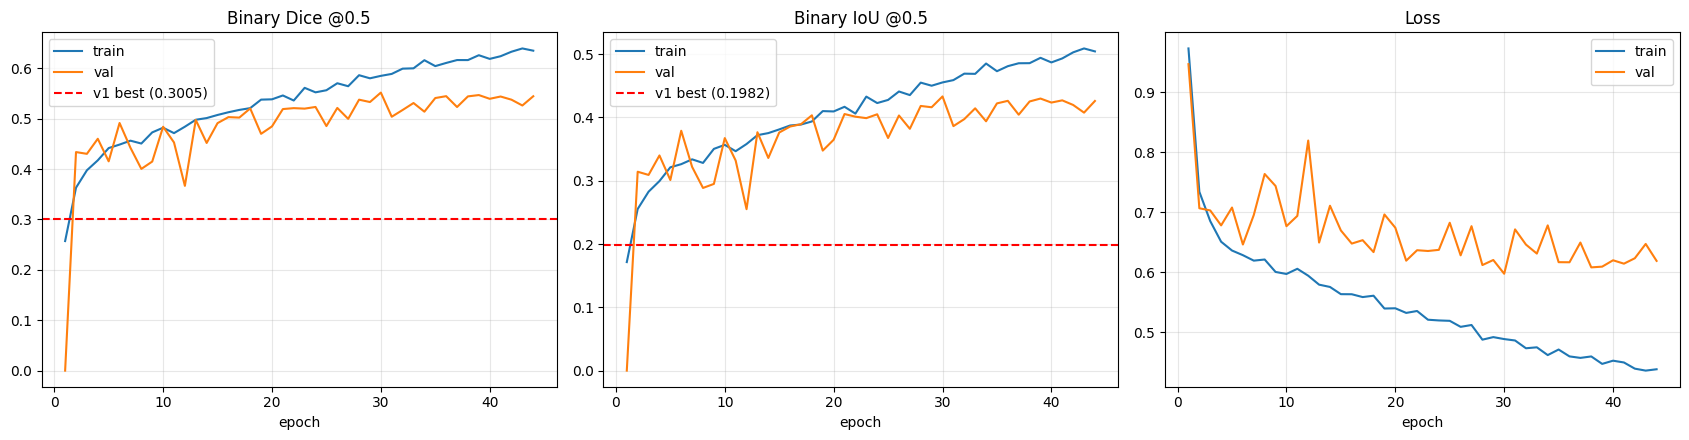

In [25]:
# ============================================================
# 20. CURVES + FIT DIAGNOSIS
# ============================================================
history_df = pd.read_csv(HISTORY_CSV)
history_df["global_epoch"] = np.arange(1, len(history_df) + 1)

assert f"val_{DICE_COL}" in history_df.columns, (
    f"Missing column val_{DICE_COL}. Found: {list(history_df.columns)}"
)

best_idx = int(history_df[f"val_{DICE_COL}"].idxmax())
best_epoch = int(history_df.loc[best_idx, "global_epoch"])
best_dice = float(history_df.loc[best_idx, f"val_{DICE_COL}"])
best_iou = float(history_df.loc[best_idx, f"val_{IOU_COL}"])
gap = float(history_df.loc[best_idx, DICE_COL]) - best_dice

if gap < 0.03:
    verdict = "STILL UNDERFITTING -> raise base_filters / LR"
elif gap > 0.15:
    verdict = "OVERFITTING -> raise dropout / weight decay further"
else:
    verdict = "healthy fit"

print("Best epoch    :", best_epoch, "of", len(history_df))
print("Best val Dice :", f"{best_dice:.4f}   (v1 = {V1_DICE:.4f})")
print("Best val IoU  :", f"{best_iou:.4f}   (v1 = {V1_IOU:.4f})")
print("Improvement   :", f"{(best_dice / V1_DICE - 1) * 100:+.1f}% vs v1")
print("Train-val gap :", f"{gap:+.4f}  ->", verdict)
print("(Note: this reads the CSVLogger history from single-checkpoint training;")
print(" if SWA won in 19b, the final evaluated model differs from 'best_epoch' here")
print(" -- Section 22 reports the number that actually matters.)")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].plot(history_df["global_epoch"], history_df[DICE_COL], label="train")
axes[0].plot(history_df["global_epoch"], history_df[f"val_{DICE_COL}"], label="val")
axes[0].axhline(V1_DICE, ls="--", c="r", label=f"v1 best ({V1_DICE:.4f})")
axes[0].set_title("Binary Dice @0.5")

axes[1].plot(history_df["global_epoch"], history_df[IOU_COL], label="train")
axes[1].plot(history_df["global_epoch"], history_df[f"val_{IOU_COL}"], label="val")
axes[1].axhline(V1_IOU, ls="--", c="r", label=f"v1 best ({V1_IOU:.4f})")
axes[1].set_title("Binary IoU @0.5")

axes[2].plot(history_df["global_epoch"], history_df["loss"], label="train")
axes[2].plot(history_df["global_epoch"], history_df["val_loss"], label="val")
axes[2].set_title("Loss")

for ax in axes:
    ax.set_xlabel("epoch"); ax.legend(); ax.grid(alpha=.3)

plt.tight_layout()
plt.savefig(RUN_DIR / f"{VARIANT}_curves.png", dpi=140)
plt.show()


Best checkpoint reloaded.


Predicting val:   0%|          | 0/114 [00:00<?, ?it/s]

Validation tensor: (455, 256, 256)
 threshold   dice    iou  precision  recall
    0.1000 0.5351 0.4175     0.4942  0.8379
    0.1500 0.5416 0.4237     0.5118  0.8187
    0.2000 0.5449 0.4270     0.5241  0.8034
    0.2500 0.5474 0.4292     0.5340  0.7909
    0.3000 0.5489 0.4307     0.5423  0.7799
    0.3500 0.5501 0.4318     0.5499  0.7699
    0.4000 0.5509 0.4325     0.5566  0.7589
    0.4500 0.5513 0.4329     0.5632  0.7490
    0.5000 0.5515 0.4331     0.5696  0.7396
    0.5500 0.5515 0.4333     0.5761  0.7302
    0.6000 0.5514 0.4331     0.5830  0.7203
    0.6500 0.5505 0.4322     0.5899  0.7089
    0.7000 0.5493 0.4310     0.5979  0.6963
    0.7500 0.5473 0.4290     0.6071  0.6809
    0.8000 0.5439 0.4255     0.6180  0.6605
    0.8500 0.5375 0.4189     0.6320  0.6314
    0.9000 0.5212 0.4026     0.6594  0.5785

Best threshold : 0.55  Dice: 0.5515


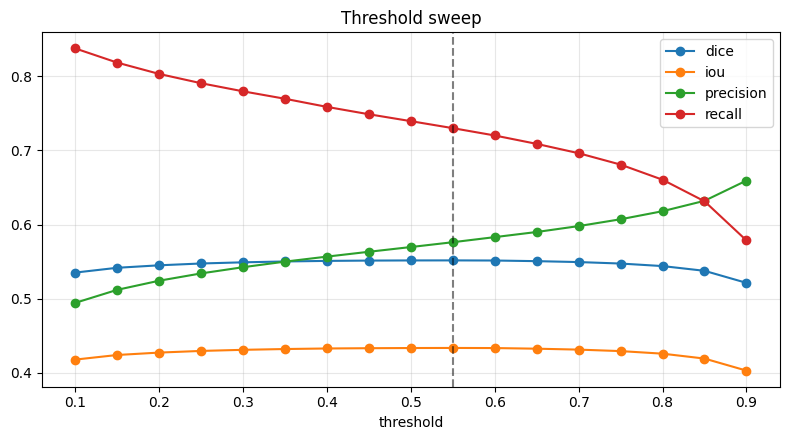

In [26]:
# ============================================================
# 21. THRESHOLD CALIBRATION
#     Reloads BEST_WEIGHTS, which Section 19b overwrites with the SWA
#     average when SWA won -- so this always calibrates against whichever
#     weights are actually going to be shipped.
# ============================================================
model.load_weights(str(BEST_WEIGHTS))
print("Best checkpoint reloaded.")

probs_list, gts_list = [], []
for xb, yb in tqdm(val_ds, desc="Predicting val"):
    out = model.predict(xb, verbose=0)
    pm = out[0] if isinstance(out, (list, tuple)) else out
    probs_list.append(pm[..., 0].astype(np.float32))
    gts_list.append(main_target(yb).numpy()[..., 0].astype(np.float32))

probs = np.concatenate(probs_list, axis=0)
gts = np.concatenate(gts_list, axis=0)
del probs_list, gts_list

assert probs.shape == gts.shape, f"shape mismatch {probs.shape} vs {gts.shape}"
assert len(probs) == len(val_df), (
    f"prediction count {len(probs)} != val rows {len(val_df)}"
)
print("Validation tensor:", probs.shape)


def sweep(probs, gts, thresholds):
    rows = []
    gt_flat = gts.reshape(gts.shape[0], -1)
    gt_sum = gt_flat.sum(1)
    pr_all = probs.reshape(probs.shape[0], -1)
    for t in thresholds:
        pr = (pr_all >= t).astype(np.float32)
        inter = (gt_flat * pr).sum(1)
        pr_sum = pr.sum(1)
        rows.append({
            "threshold": float(t),
            "dice": float(((2 * inter + 1e-6) / (gt_sum + pr_sum + 1e-6)).mean()),
            "iou": float(((inter + 1e-6) / (gt_sum + pr_sum - inter + 1e-6)).mean()),
            "precision": float(((inter + 1e-6) / (pr_sum + 1e-6)).mean()),
            "recall": float(((inter + 1e-6) / (gt_sum + 1e-6)).mean()),
        })
    return pd.DataFrame(rows)


sweep_df = sweep(probs, gts, THRESHOLD_GRID)
sweep_df.to_csv(RUN_DIR / f"{VARIANT}_threshold_sweep.csv", index=False)

best_row = sweep_df.loc[sweep_df["dice"].idxmax()]
BEST_THRESHOLD = float(best_row["threshold"])

print(sweep_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print()
print("Best threshold :", BEST_THRESHOLD, " Dice:", f"{best_row['dice']:.4f}")

plt.figure(figsize=(8, 4.5))
for col in ("dice", "iou", "precision", "recall"):
    plt.plot(sweep_df["threshold"], sweep_df[col], marker="o", label=col)
plt.axvline(BEST_THRESHOLD, ls="--", c="k", alpha=.5)
plt.xlabel("threshold"); plt.legend(); plt.grid(alpha=.3)
plt.title("Threshold sweep")
plt.tight_layout()
plt.savefig(RUN_DIR / f"{VARIANT}_threshold_sweep.png", dpi=140)
plt.show()


In [27]:
# ============================================================
# 22. FINAL EVAL + LESION-SIZE BREAKDOWN
# ============================================================
pred_bin = (probs >= BEST_THRESHOLD).astype(np.float32)
gt_flat = gts.reshape(gts.shape[0], -1)
pr_flat = pred_bin.reshape(pred_bin.shape[0], -1)

inter = (gt_flat * pr_flat).sum(1)
dice_per_image = (2 * inter + 1e-6) / (gt_flat.sum(1) + pr_flat.sum(1) + 1e-6)
iou_per_image = (inter + 1e-6) / (gt_flat.sum(1) + pr_flat.sum(1) - inter + 1e-6)

final_dice = float(dice_per_image.mean())
final_iou = float(iou_per_image.mean())

print("=" * 60)
print("FINAL VALIDATION --", VARIANT)
print("=" * 60)
print(f"Threshold        : {BEST_THRESHOLD}")
print(f"Dice             : {final_dice:.4f}   (v1: {V1_DICE:.4f})")
print(f"IoU              : {final_iou:.4f}   (v1: {V1_IOU:.4f})")
print(f"Dice std         : {float(dice_per_image.std()):.4f}")
print(f"Images Dice>0.5  : {int((dice_per_image > 0.5).sum())} / {len(dice_per_image)}")
print(f"Images Dice<0.1  : {int((dice_per_image < 0.1).sum())} / {len(dice_per_image)}")

size_df = val_df.copy()
size_df["dice"] = dice_per_image
size_df["iou"] = iou_per_image
size_df["size_bin"] = pd.cut(size_df["lesion_frac"],
                             bins=SIZE_BIN_EDGES, labels=SIZE_BIN_LABELS)

breakdown = size_df.groupby("size_bin", observed=True).agg(
    images=("dice", "size"), mean_dice=("dice", "mean"), mean_iou=("iou", "mean")
).round(4)

print()
print("Performance by lesion size (compare against the previous run's table:")
print("  <1%: 0.248 | 1-5%: 0.466 | 5-15%: 0.664 | >15%: 0.781):")
print(breakdown.to_string())
breakdown.to_csv(RUN_DIR / f"{VARIANT}_size_breakdown.csv")


FINAL VALIDATION -- mu_d_deepsup
Threshold        : 0.55
Dice             : 0.5515   (v1: 0.3005)
IoU              : 0.4333   (v1: 0.1982)
Dice std         : 0.2830
Images Dice>0.5  : 269 / 455
Images Dice<0.1  : 38 / 455

Performance by lesion size (compare against the previous run's table:
  <1%: 0.248 | 1-5%: 0.466 | 5-15%: 0.664 | >15%: 0.781):
          images  mean_dice  mean_iou
size_bin                             
<1%           59     0.2623    0.1775
1-5%         136     0.4359    0.3106
5-15%        122     0.6354    0.5003
>15%         138     0.7150    0.6042


In [28]:
# ============================================================
# 23. SAVE ARTIFACTS + APPEND TO ABLATION LOG
# ============================================================
model.save(str(FINAL_MODEL))
model.save_weights(str(FINAL_WEIGHTS))

with open(RUN_DIR / f"{ABLATION_ARM}_architecture.json", "w") as f:
    f.write(model.to_json())

on_disk_mb = FINAL_MODEL.stat().st_size / (1024 ** 2)
weights_mb = FINAL_WEIGHTS.stat().st_size / (1024 ** 2)

with open(RUN_DIR / f"{ABLATION_ARM}_inference_config.json", "w") as f:
    json.dump({
        "ablation_arm": ABLATION_ARM, "family": "Mobile-UNet",
        "img_size": IMG_SIZE, "letterbox": LETTERBOX_RESIZE,
        "input_range": "[0,255] float32 (model rescales internally)",
        "best_threshold": BEST_THRESHOLD,
        "val_dice": final_dice, "val_iou": final_iou,
        "total_params": total_params, "fp32_mb": round(fp32_mb, 2),
        "keras_file_mb": round(on_disk_mb, 2),
        "used_swa": bool(swa_model is not None and swa_dice is not None
                          and swa_dice > best_dice_single),
    }, f, indent=2)

# ---- Ablation log row: flags used + overall metrics + per-size-bin Dice ----
bin_dice_by_label = {lbl: np.nan for lbl in SIZE_BIN_LABELS}
bin_n_by_label = {lbl: 0 for lbl in SIZE_BIN_LABELS}
for lbl in SIZE_BIN_LABELS:
    if lbl in breakdown.index:
        bin_dice_by_label[lbl] = float(breakdown.loc[lbl, "mean_dice"])
        bin_n_by_label[lbl] = int(breakdown.loc[lbl, "images"])

ablation_row = {
    "ablation_arm": ABLATION_ARM,
    "use_crop": USE_CROP, "use_oversample": USE_OVERSAMPLE,
    "use_elastic": USE_ELASTIC, "use_cutout": USE_CUTOUT, "use_swa": USE_SWA,
    "weight_decay": WEIGHT_DECAY, "dropout": DROPOUT,
    "total_epochs_budget": TOTAL_EPOCHS, "epochs_run": len(history_df),
    "best_epoch": best_epoch, "best_threshold": BEST_THRESHOLD,
    "val_dice_overall": round(final_dice, 4),
    "val_iou_overall": round(final_iou, 4),
    "train_val_gap": round(gap, 4),
    "dice_lt1pct": round(bin_dice_by_label["<1%"], 4) if pd.notna(bin_dice_by_label["<1%"]) else np.nan,
    "n_lt1pct": bin_n_by_label["<1%"],
    "dice_1to5pct": round(bin_dice_by_label["1-5%"], 4) if pd.notna(bin_dice_by_label["1-5%"]) else np.nan,
    "n_1to5pct": bin_n_by_label["1-5%"],
    "dice_5to15pct": round(bin_dice_by_label["5-15%"], 4) if pd.notna(bin_dice_by_label["5-15%"]) else np.nan,
    "n_5to15pct": bin_n_by_label["5-15%"],
    "dice_gt15pct": round(bin_dice_by_label[">15%"], 4) if pd.notna(bin_dice_by_label[">15%"]) else np.nan,
    "n_gt15pct": bin_n_by_label[">15%"],
    "training_minutes": round(training_seconds / 60.0, 2),
}

# Reference rows so the log always shows where you started from, even on
# the very first ablation run.
REFERENCE_ROWS = [
    {
        "ablation_arm": "REFERENCE_v1_original", "use_crop": False, "use_oversample": False,
        "use_elastic": False, "use_cutout": False, "use_swa": False,
        "weight_decay": np.nan, "dropout": np.nan, "total_epochs_budget": 55,
        "epochs_run": 55, "best_epoch": 55, "best_threshold": 0.5,
        "val_dice_overall": 0.3005, "val_iou_overall": 0.1982, "train_val_gap": 0.0093,
        "dice_lt1pct": np.nan, "n_lt1pct": np.nan, "dice_1to5pct": np.nan, "n_1to5pct": np.nan,
        "dice_5to15pct": np.nan, "n_5to15pct": np.nan, "dice_gt15pct": np.nan, "n_gt15pct": np.nan,
        "training_minutes": 236.43,
    },
    {
        "ablation_arm": "REFERENCE_mu_b_tuned_first_run", "use_crop": False, "use_oversample": False,
        "use_elastic": False, "use_cutout": False, "use_swa": False,
        "weight_decay": 1e-5, "dropout": 0.10, "total_epochs_budget": 50,
        "epochs_run": 50, "best_epoch": 20, "best_threshold": 0.4,
        "val_dice_overall": 0.5864, "val_iou_overall": 0.4741, "train_val_gap": 0.12,
        "dice_lt1pct": 0.2476, "n_lt1pct": 59, "dice_1to5pct": 0.4661, "n_1to5pct": 136,
        "dice_5to15pct": 0.6640, "n_5to15pct": 122, "dice_gt15pct": 0.7813, "n_gt15pct": 138,
        "training_minutes": np.nan,
    },
    {
        "ablation_arm": "REFERENCE_v2_all_combined_BROKEN", "use_crop": True, "use_oversample": True,
        "use_elastic": True, "use_cutout": True, "use_swa": True,
        "weight_decay": 5e-5, "dropout": 0.15, "total_epochs_budget": 50,
        "epochs_run": np.nan, "best_epoch": np.nan, "best_threshold": np.nan,
        "val_dice_overall": np.nan, "val_iou_overall": np.nan, "train_val_gap": np.nan,
        "dice_lt1pct": 0.0958, "n_lt1pct": 59, "dice_1to5pct": 0.3257, "n_1to5pct": 136,
        "dice_5to15pct": 0.6086, "n_5to15pct": 122, "dice_gt15pct": 0.7358, "n_gt15pct": 138,
        "training_minutes": np.nan,
    },
]

if ABLATION_CSV.exists():
    log = pd.read_csv(ABLATION_CSV)
    log = log[log["ablation_arm"] != ABLATION_ARM]
    log = pd.concat([log, pd.DataFrame([ablation_row])], ignore_index=True)
    existing_refs = set(log["ablation_arm"])
    missing_refs = [r for r in REFERENCE_ROWS if r["ablation_arm"] not in existing_refs]
    if missing_refs:
        log = pd.concat([pd.DataFrame(missing_refs), log], ignore_index=True)
else:
    log = pd.DataFrame(REFERENCE_ROWS + [ablation_row])

log.to_csv(ABLATION_CSV, index=False)

print("Saved:", FINAL_MODEL, f"({on_disk_mb:.2f} MB on disk)")
print()
print("=" * 130)
print("ABLATION LOG --", ABLATION_CSV)
print("=" * 130)
cols = ["ablation_arm", "use_crop", "use_oversample", "use_elastic", "use_cutout",
        "val_dice_overall", "dice_lt1pct", "dice_1to5pct", "dice_5to15pct", "dice_gt15pct"]
print(log[cols].to_string(index=False))
print()
print("Read this top to bottom once all arms are done: any arm whose dice_lt1pct or")
print("dice_1to5pct is BELOW the REFERENCE_mu_b_tuned_first_run row made small lesions")
print("worse and should stay OFF in combined_winners, regardless of its overall Dice.")


Saved: /kaggle/working/Segmentation Output/run_v4_deepsup_all_fixes/v4_deepsup_all_fixes_final.keras (14.14 MB on disk)

ABLATION LOG -- /kaggle/working/Segmentation Output/ablation_results.csv
                    ablation_arm  use_crop  use_oversample  use_elastic  use_cutout  val_dice_overall  dice_lt1pct  dice_1to5pct  dice_5to15pct  dice_gt15pct
           REFERENCE_v1_original     False           False        False       False            0.3005          NaN           NaN            NaN           NaN
  REFERENCE_mu_b_tuned_first_run     False           False        False       False            0.5864       0.2476        0.4661         0.6640        0.7813
REFERENCE_v2_all_combined_BROKEN      True            True         True        True               NaN       0.0958        0.3257         0.6086        0.7358
            v4_deepsup_all_fixes      True            True         True        True            0.5515       0.2623        0.4359         0.6354        0.7150

Read this top t

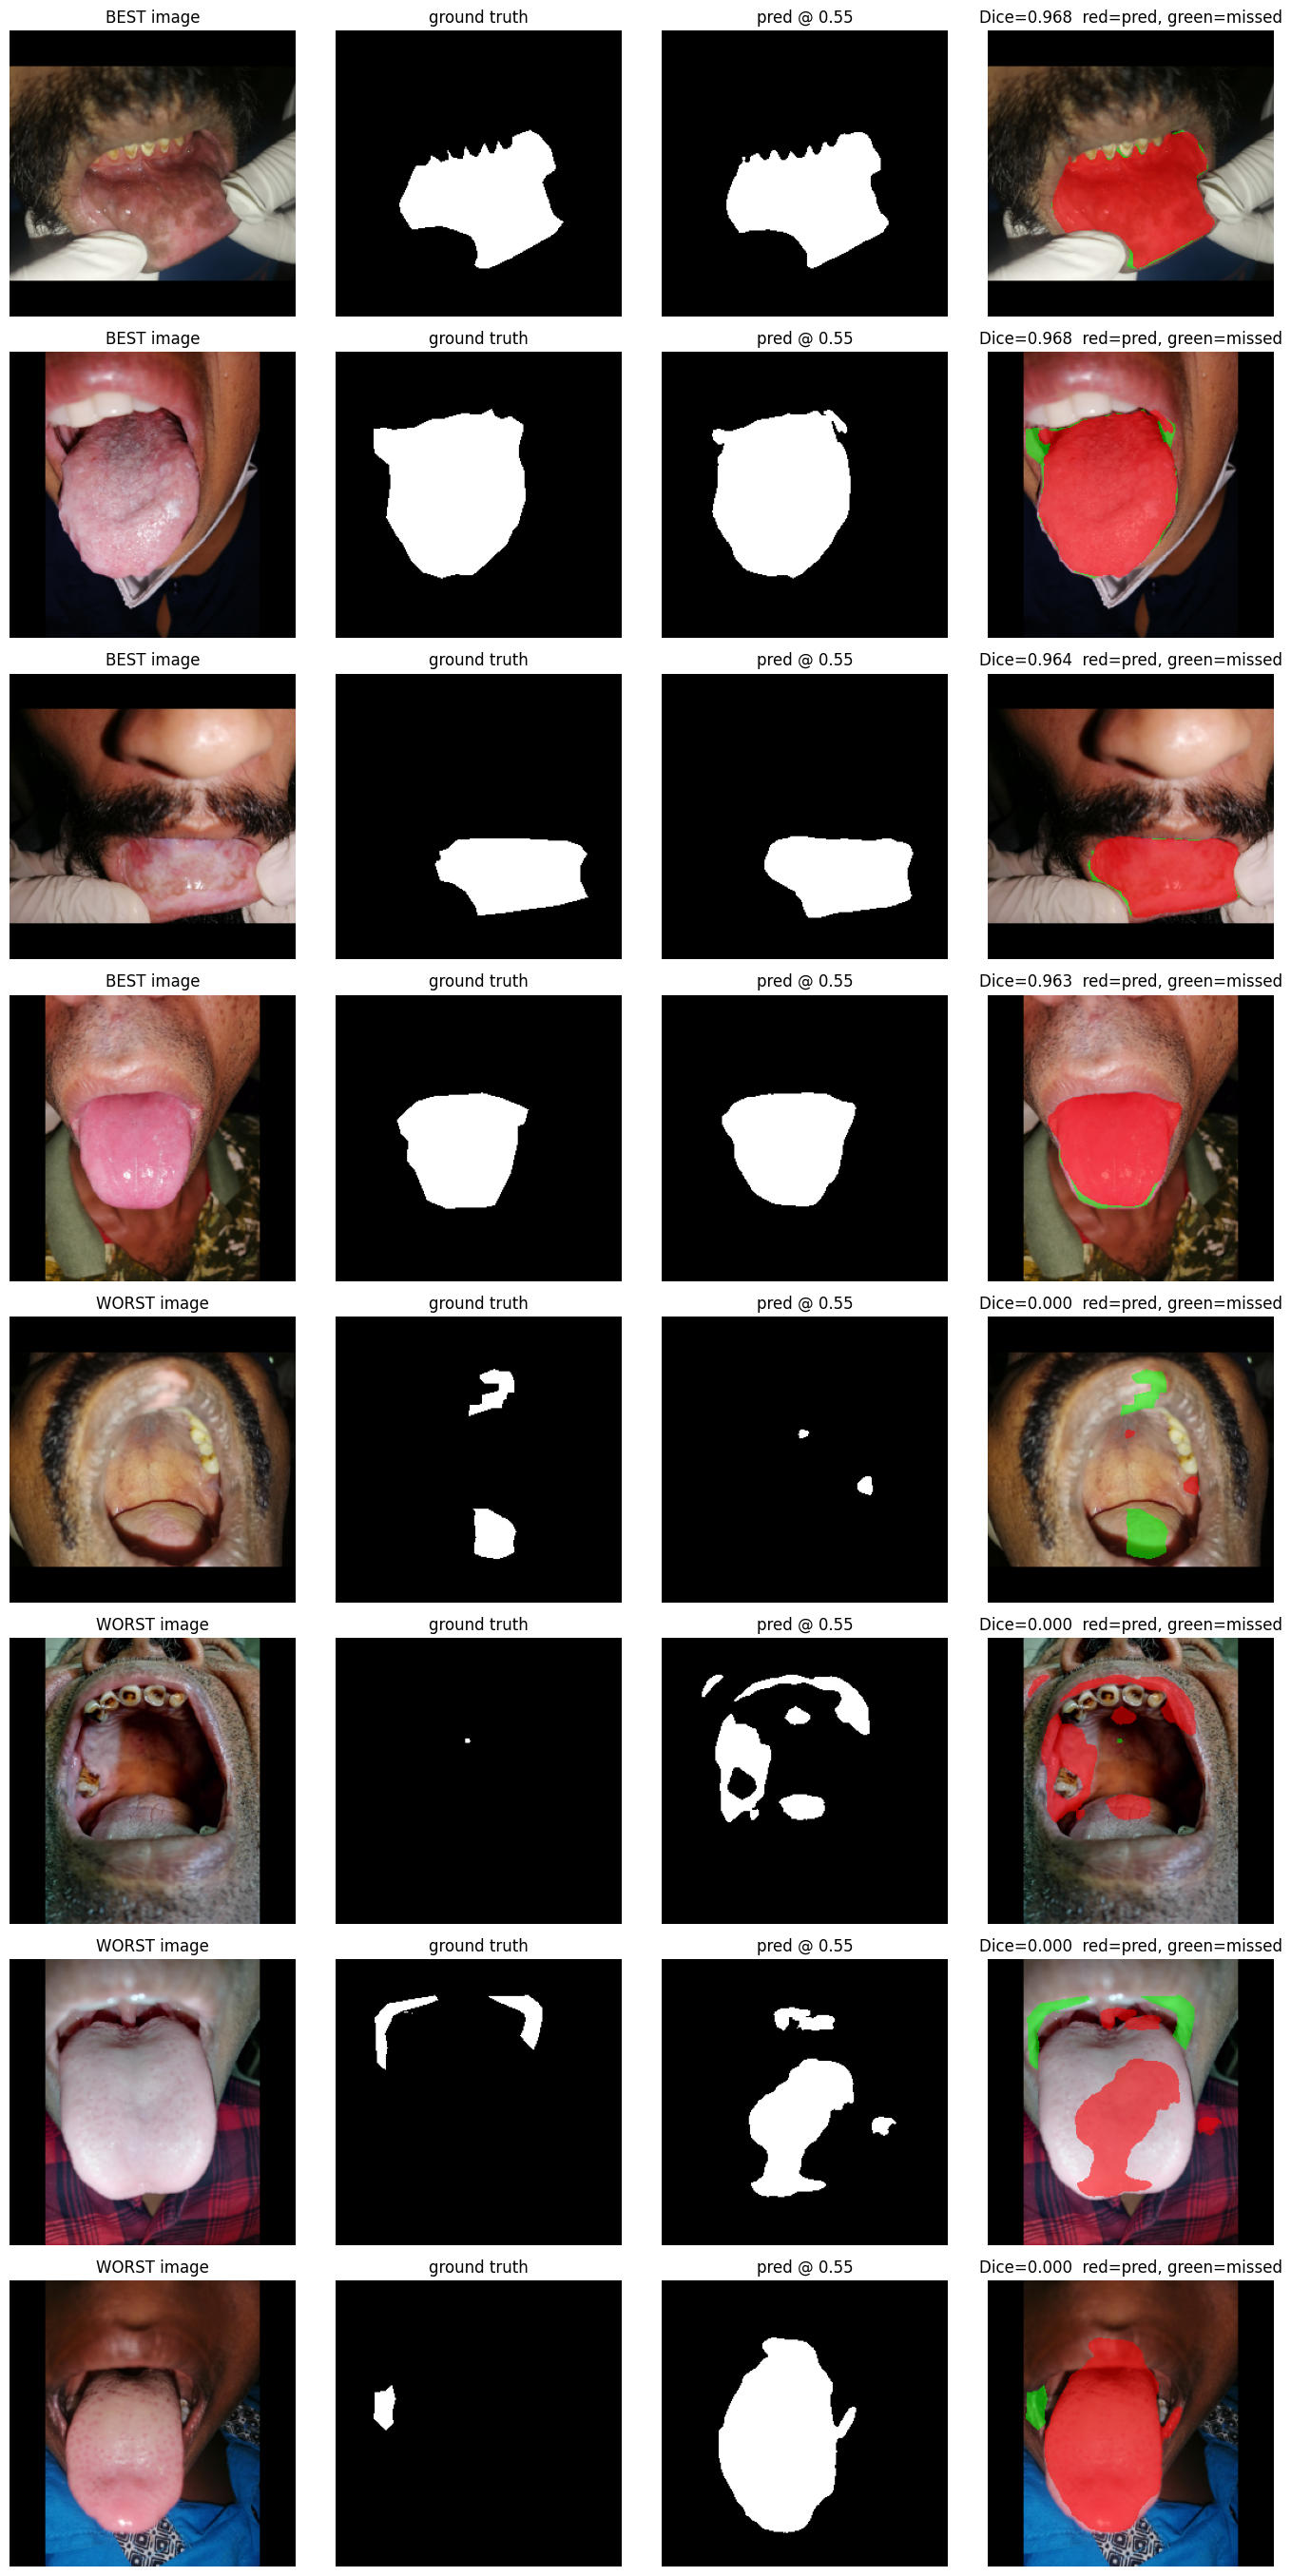

In [29]:
# ============================================================
# 24. QUALITATIVE PREDICTIONS (4 best + 4 worst)
# ============================================================
SEG_DIR = RUN_DIR / "final_segmented"
SEG_DIR.mkdir(parents=True, exist_ok=True)

order = np.argsort(-dice_per_image)
show_idx = list(order[:4]) + list(order[-4:])

fig, axes = plt.subplots(len(show_idx), 4, figsize=(14, 3.4 * len(show_idx)))

for r, idx in enumerate(show_idx):
    idx = int(idx)
    row = val_df.iloc[idx]

    img = safe_imread(row["image_path"], cv2.IMREAD_COLOR)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = (letterbox(img, IMG_SIZE, cv2.INTER_AREA) if LETTERBOX_RESIZE
           else cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA))

    gt = (gts[idx] * 255).astype(np.uint8)
    pm = (pred_bin[idx] * 255).astype(np.uint8)

    ov = img.copy()
    hit = pm > 0
    miss = (gt > 0) & (pm == 0)
    ov[hit] = (0.45 * ov[hit] + 0.55 * np.array([255, 0, 0])).astype(np.uint8)
    ov[miss] = (0.45 * ov[miss] + 0.55 * np.array([0, 255, 0])).astype(np.uint8)

    tag = "BEST" if r < 4 else "WORST"
    axes[r, 0].imshow(img);             axes[r, 0].set_title(f"{tag} image")
    axes[r, 1].imshow(gt, cmap="gray"); axes[r, 1].set_title("ground truth")
    axes[r, 2].imshow(pm, cmap="gray"); axes[r, 2].set_title(f"pred @ {BEST_THRESHOLD}")
    axes[r, 3].imshow(ov)
    axes[r, 3].set_title(f"Dice={dice_per_image[idx]:.3f}  red=pred, green=missed")
    for c in range(4):
        axes[r, c].axis("off")

    cv2.imwrite(str(SEG_DIR / f"{row['image_id']}_pred.png"),
                cv2.cvtColor(ov, cv2.COLOR_RGB2BGR))

plt.tight_layout()
plt.savefig(RUN_DIR / f"{VARIANT}_predictions.png", dpi=140)
plt.show()


In [30]:
# ============================================================
# 25. FINAL AUDIT
# ============================================================
required = [
    BEST_WEIGHTS, FINAL_MODEL, FINAL_WEIGHTS, HISTORY_CSV,
    RUN_DIR / f"{ABLATION_ARM}_architecture.json",
    RUN_DIR / f"{ABLATION_ARM}_inference_config.json",
    RUN_DIR / f"{VARIANT}_threshold_sweep.csv",
    RUN_DIR / f"{VARIANT}_size_breakdown.csv",
    RUN_DIR / f"{VARIANT}_curves.png",
    RUN_DIR / f"{VARIANT}_predictions.png",
    RUN_DIR / "jpeg_integrity_scan.csv",
    ABLATION_CSV,
]
missing = [str(p) for p in required if not p.exists()]
print("Missing artifacts:", missing if missing else "none")
assert not missing, "STOP: artifacts missing."

_swa_won = bool(USE_SWA and swa_model is not None and swa_dice is not None
               and best_dice_single is not None and swa_dice > best_dice_single)

print()
print("Audit")
print("  Architecture family    : Mobile-UNet (depthwise separable) ONLY")
print("  External backbone      : NONE")
print("  Pretrained weights     : NONE")
print("  Transfer learning      : NONE")
print("  Ablation arm            :", ABLATION_ARM)
print("  Base filters           :", BASE_FILTERS)
print("  Image size             :", IMG_SIZE)
print("  Effective batch        :", EFFECTIVE_BATCH, "via grad_accum_steps =", GRAD_ACCUM_STEPS)
print("  use_crop (scale-consist):", USE_CROP, " prob:", TRAIN_CROP_PROB)
print("  use_oversample          :", USE_OVERSAMPLE, SIZE_BIN_TARGET_FREQ if USE_OVERSAMPLE else "")
print("  use_elastic / use_cutout:", USE_ELASTIC, "/", USE_CUTOUT)
print("  weight_decay / dropout  :", WEIGHT_DECAY, "/", DROPOUT)
print("  SWA requested / applied :", USE_SWA, "/", _swa_won)
print("  Residual sep blocks    :", USE_RESIDUAL)
print("  Attention gates        :", USE_GATES)
print("  CBAM bottleneck        :", USE_CBAM)
print("  ASPP bottleneck        :", USE_ASPP)
print("  Deep supervision       :", USE_DEEP_SUP)
print("  Layer-name registry    : ACTIVE (duplicate names impossible)")
print("  Optimizer              : AdamW warmup+cosine (no ReduceLROnPlateau)")
print("  Loss                   : 0.5*BCE + 0.5*FocalTversky(0.3, 0.7)")
print("  Custom objects         : registered (save/load safe)")
print("  Resize                 :", "letterbox" if LETTERBOX_RESIZE else "square squash")
print("  Split                  : stratified by lesion area, leak-checked")
print("  Threshold              : calibrated ->", BEST_THRESHOLD)
print("  Epoch budget           :", TOTAL_EPOCHS, " (epochs actually run:", len(history_df), ")")
print()
print(f"  SIZE    : {total_params:,} params, {fp32_mb:.2f} MB FP32, {on_disk_mb:.2f} MB on disk")
print(f"  RESULT  : val Dice {final_dice:.4f}  val IoU {final_iou:.4f}")
print(f"            (reference points: v1={0.3005:.4f}, first mu_b_tuned run={0.5864:.4f})")
print()
print("Size breakdown this arm (compare against the reference rows in ablation_results.csv):")
print(breakdown.to_string())
print()
print("This arm's row has been appended to:", ABLATION_CSV)
print("Once all arms are run, read that CSV to decide what goes into combined_winners.")


Missing artifacts: none

Audit
  Architecture family    : Mobile-UNet (depthwise separable) ONLY
  External backbone      : NONE
  Pretrained weights     : NONE
  Transfer learning      : NONE
  Ablation arm            : v4_deepsup_all_fixes
  Base filters           : 32
  Image size             : 256
  Effective batch        : 4 via grad_accum_steps = 1
  use_crop (scale-consist): True  prob: 0.5
  use_oversample          : True {'<1%': 0.35, '1-5%': 0.3, '5-15%': 0.2, '>15%': 0.15}
  use_elastic / use_cutout: True / True
  weight_decay / dropout  : 3e-05 / 0.12
  SWA requested / applied : True / False
  Residual sep blocks    : True
  Attention gates        : True
  CBAM bottleneck        : True
  ASPP bottleneck        : True
  Deep supervision       : True
  Layer-name registry    : ACTIVE (duplicate names impossible)
  Optimizer              : AdamW warmup+cosine (no ReduceLROnPlateau)
  Loss                   : 0.5*BCE + 0.5*FocalTversky(0.3, 0.7)
  Custom objects         : regis

## What to do with the result

Section 25's audit prints this run's overall Dice, IoU, and the full lesion-size
breakdown, and appends one row to `ablation_results.csv` (in `OUTPUT_ROOT`) alongside
reference rows for your original `mu_b_tuned` run (0.586 overall, `<1%`=0.248) and the
broken v2 run (`<1%`=0.096). Read that CSV first — it's the fastest way to see whether
this consolidated run actually beat both.

**If Section 20 says STILL UNDERFITTING** (train/val gap < 0.03): the model isn't using
its capacity. Raise `base_filters` for `mu_d_deepsup` in the `VARIANTS` dict (32 → 48) and
rerun.

**If it still says OVERFITTING** (gap > 0.15): raise `WEIGHT_DECAY` (3e-5 → 5e-5) and
`DROPOUT` (0.12 → 0.18) in Section 2 before touching capacity.

**If the size-breakdown table still shows `<1%` and `1-5%` lagging far behind `>15%`**:
since cutout and crop are now bug-fixed rather than off, the next lever is turning
`TRAIN_CROP_PROB` and `SIZE_BIN_TARGET_FREQ` further toward small lesions, not adding
more augmentation types. If small lesions *still* don't move, that's a signal worth
taking seriously — it may mean the ~1,800-image, no-pretrained-encoder constraint has a
real ceiling for sub-1%-area objects (see the earlier discussion on why 90%+ Dice
generally requires a pretrained encoder or far more data), and the next lever isn't in
this notebook at all.

**If you want to isolate which of the four training-recipe changes (crop / oversample /
elastic / cutout) is actually responsible for whatever this run's result is**: that's
what the previous ablation notebook does, one flag at a time across separate kernel
sessions. This notebook trades that isolation for a single run: use it when you want an
answer now, use the ablation notebook when you want to know *why*.
